# Loop Engineering for AI Agents: an order desk you can watch think

This notebook is the hands-on companion to the article **Loop Engineering for AI Agents: Stop Writing Prompts, Start Designing Loops**.

We build a small online shop with a real **SQLite database**, give an AI agent a set of tools to place, cancel, return and refund orders, and then wrap that agent in a loop. Every idea from the article becomes something you can run and see:

| # | Scenario | What you will see |
|---|---|---|
| 1 | Prompt engineering vs loop engineering | Six hand-written prompts replaced by one goal |
| 2 | The core loop | Goal, Act, Observe, Adjust, pass by pass, including a failed action the agent recovers from |
| 3 | Weak goals vs verifiable goals | A loop that stops too early, one that never stops, and one that knows when it is done |
| 4 | Triggers | A hook fired by a customer message and a nightly scheduled job |
| 5 | Context and skills | The same job with bloated context vs engineered context |
| 6 | The spine (`progress.md`) | A payment timeout that causes a double refund, and the memory that prevents it |
| 7 | Tools | MCP-style tool schemas, validation and a tool usage log |
| 8 | Checker subagent | A wrong refund caught *before* the money leaves |
| 9 | Intent debt (`AGENTS.md`) | A loop that "succeeds" while leaking revenue |
| 10 | Human in the loop | An approval gate and a plain-language review card |
| 11 | Everything together | Seven customers, one engineered loop, a reconciliation dashboard |
| UI | **The Order Desk (Gradio app)** | Pick a customer and an agent (mock or Claude), switch loop parts on and off, run it live, inspect the database |

**What is real and what is simulated.** The shop is a real SQLite database, the tools really run SQL, the goal checks really query the tables, and the spine, checker and human gate are all real code. The only thing that can be simulated is the agent's "brain":

* **Mock agent (default):** plain Python rules choose each action. No API key, no cost, and every lesson reproduces exactly, including the mistakes.
* **Claude agent:** set `USE_CLAUDE = True` (or pick Claude in the Order Desk app) and a real model chooses each action from the same context and the same tools. Results will vary from run to run, which is exactly why the loop around it matters.

**How to run it.** Run the cells from top to bottom: install, set up, optionally add your API key, then the scenarios and the app.

## How the system fits together

Before any code, here is the whole system on one page. Every box is labelled with the actual function or class you will meet later, so you can use this picture as a map while you read.

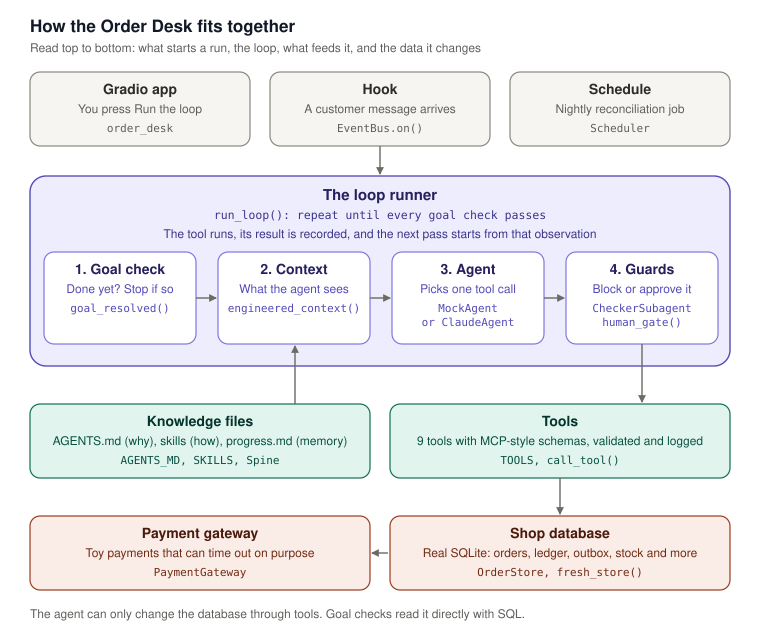

In [1]:
#@title Architecture diagram (run this cell to show it)
from IPython.display import SVG, display

ARCHITECTURE_SVG = r'''<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 760 640" width="760" height="640" role="img" aria-label="Order Desk architecture">
<defs><marker id="ah" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M1 1L9 5L1 9z" fill="#6B6A64"/></marker></defs>
<rect x="0" y="0" width="760" height="640" fill="#FFFFFF"/>
<text x="30" y="32" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="17" font-weight="700" fill="#111827">How the Order Desk fits together</text>
<text x="30" y="52" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#5F5E5A">Read top to bottom: what starts a run, the loop, what feeds it, and the data it changes</text>
<rect x="30" y="72" width="220" height="74" rx="10" fill="#F6F5F1" stroke="#88877F" stroke-width="1.2"/>
<text x="140.0" y="94" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#2C2C2A">Gradio app</text>
<text x="140.0" y="113" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#5F5E5A">You press Run the loop</text>
<text x="140.0" y="132" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#5F5E5A">order_desk</text>
<rect x="270" y="72" width="220" height="74" rx="10" fill="#F6F5F1" stroke="#88877F" stroke-width="1.2"/>
<text x="380.0" y="94" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#2C2C2A">Hook</text>
<text x="380.0" y="113" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#5F5E5A">A customer message arrives</text>
<text x="380.0" y="132" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#5F5E5A">EventBus.on()</text>
<rect x="510" y="72" width="220" height="74" rx="10" fill="#F6F5F1" stroke="#88877F" stroke-width="1.2"/>
<text x="620.0" y="94" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#2C2C2A">Schedule</text>
<text x="620.0" y="113" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#5F5E5A">Nightly reconciliation job</text>
<text x="620.0" y="132" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#5F5E5A">Scheduler</text>
<path d="M380 146 V174" fill="none" stroke="#6B6A64" stroke-width="1.4" marker-end="url(#ah)"/>
<rect x="30" y="176" width="700" height="190" rx="16" fill="#EEEDFE" stroke="#534AB7" stroke-width="1.4"/>
<text x="380" y="200" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="15" font-weight="700" fill="#26215C">The loop runner</text>
<text x="380" y="219" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11.5" fill="#3C3489">run_loop(): repeat until every goal check passes</text>
<rect x="44" y="252" width="152" height="92" rx="10" fill="#FFFFFF" stroke="#7F77DD" stroke-width="1.2"/>
<text x="120.0" y="274" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#26215C">1. Goal check</text>
<text x="120.0" y="293" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#534AB7">Done yet? Stop if so</text>
<text x="120.0" y="312" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#534AB7">goal_resolved()</text>
<rect x="218" y="252" width="152" height="92" rx="10" fill="#FFFFFF" stroke="#7F77DD" stroke-width="1.2"/>
<text x="294.0" y="274" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#26215C">2. Context</text>
<text x="294.0" y="293" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#534AB7">What the agent sees</text>
<text x="294.0" y="312" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#534AB7">engineered_context()</text>
<rect x="392" y="252" width="152" height="92" rx="10" fill="#FFFFFF" stroke="#7F77DD" stroke-width="1.2"/>
<text x="468.0" y="274" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#26215C">3. Agent</text>
<text x="468.0" y="293" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#534AB7">Picks one tool call</text>
<text x="468.0" y="312" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#534AB7">MockAgent</text>
<text x="468.0" y="326" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#534AB7">or ClaudeAgent</text>
<rect x="566" y="252" width="152" height="92" rx="10" fill="#FFFFFF" stroke="#7F77DD" stroke-width="1.2"/>
<text x="642.0" y="274" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#26215C">4. Guards</text>
<text x="642.0" y="293" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#534AB7">Block or approve it</text>
<text x="642.0" y="312" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#534AB7">CheckerSubagent</text>
<text x="642.0" y="326" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#534AB7">human_gate()</text>
<path d="M196 298 H216" fill="none" stroke="#6B6A64" stroke-width="1.4" marker-end="url(#ah)"/>
<path d="M370 298 H390" fill="none" stroke="#6B6A64" stroke-width="1.4" marker-end="url(#ah)"/>
<path d="M544 298 H564" fill="none" stroke="#6B6A64" stroke-width="1.4" marker-end="url(#ah)"/>
<text x="380" y="238" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#3C3489">The tool runs, its result is recorded, and the next pass starts from that observation</text>
<rect x="30" y="404" width="340" height="74" rx="10" fill="#E1F5EE" stroke="#0F6E56" stroke-width="1.2"/>
<text x="200.0" y="426" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#04342C">Knowledge files</text>
<text x="200.0" y="445" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#085041">AGENTS.md (why), skills (how), progress.md (memory)</text>
<text x="200.0" y="464" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#085041">AGENTS_MD, SKILLS, Spine</text>
<rect x="390" y="404" width="340" height="74" rx="10" fill="#E1F5EE" stroke="#0F6E56" stroke-width="1.2"/>
<text x="560.0" y="426" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#04342C">Tools</text>
<text x="560.0" y="445" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#085041">9 tools with MCP-style schemas, validated and logged</text>
<text x="560.0" y="464" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#085041">TOOLS, call_tool()</text>
<path d="M295 404 V346" fill="none" stroke="#6B6A64" stroke-width="1.4" marker-end="url(#ah)"/>
<path d="M642 344 V402" fill="none" stroke="#6B6A64" stroke-width="1.4" marker-end="url(#ah)"/>
<rect x="30" y="516" width="340" height="74" rx="10" fill="#FAECE7" stroke="#993C1D" stroke-width="1.2"/>
<text x="200.0" y="538" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#4A1B0C">Payment gateway</text>
<text x="200.0" y="557" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#712B13">Toy payments that can time out on purpose</text>
<text x="200.0" y="576" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#712B13">PaymentGateway</text>
<rect x="390" y="516" width="340" height="74" rx="10" fill="#FAECE7" stroke="#993C1D" stroke-width="1.2"/>
<text x="560.0" y="538" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="14" font-weight="600" fill="#4A1B0C">Shop database</text>
<text x="560.0" y="557" text-anchor="middle" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#712B13">Real SQLite: orders, ledger, outbox, stock and more</text>
<text x="560.0" y="576" text-anchor="middle" font-family="ui-monospace, SFMono-Regular, Menlo, Consolas, monospace" font-size="11" fill="#712B13">OrderStore, fresh_store()</text>
<path d="M560 478 V514" fill="none" stroke="#6B6A64" stroke-width="1.4" marker-end="url(#ah)"/>
<path d="M388 553 H372" fill="none" stroke="#6B6A64" stroke-width="1.4" marker-end="url(#ah)"/>
<text x="30" y="618" font-family="-apple-system, Segoe UI, Helvetica, Arial, sans-serif" font-size="12" fill="#5F5E5A">The agent can only change the database through tools. Goal checks read it directly with SQL.</text>
</svg>'''

display(SVG(ARCHITECTURE_SVG))

### What happens in one pass

1. **Something starts the run.** You press *Run the loop* in the Gradio app, a customer message fires a **hook**, or the nightly **schedule** finds a stuck order.
2. **Goal check.** The loop runs the goal's checks against the database with SQL. If every check passes, it stops. This is the only thing that decides "done".
3. **Context.** The loop builds what the agent may see on this pass: the request, a compacted order snapshot, `AGENTS.md`, any matching skill, the spine (`progress.md`) and the last observation.
4. **Agent.** The agent reads that context and chooses **exactly one** tool call.
5. **Guards.** The checker subagent recalculates any refund before money moves, and the human gate pauses refunds over $500 for a person to approve.
6. **Tool.** If approved, the tool runs against the SQLite database (and the payment gateway, for money). Its result becomes the observation that the next pass starts from.

### Three ideas that make the design work

* **The agent is a plug-in.** `MockAgent` (no key) and `ClaudeAgent` share one method, `next_action(context)`. Swap one for the other and nothing else changes.
* **The agent cannot touch the data directly.** Every change goes through a validated, logged tool, and every "are we done?" decision is made by code reading the database, not by the agent saying so.
* **Knowledge lives in plain files.** The *why* (`AGENTS.md`), the *how* (skills) and the *memory* (`progress.md`) are markdown you can open, edit and switch on or off to see what each one contributes.

### Where each part lives in this notebook

* **Part A:** the shop database (`OrderStore`, `fresh_store`) and the payment gateway
* **Part B:** the tools (`TOOLS`, `call_tool`)
* **Part C:** the policy and goals (`policy_refund`, `goal_resolved`)
* **Part D:** the knowledge files (`AGENTS_MD`, `SKILLS`)
* **Part E:** context builders (`engineered_context`, `naive_context`)
* **Part F:** the agents (`MockAgent`, `ClaudeAgent`)
* **Part G:** the spine, checker and human gate (`Spine`, `CheckerSubagent`, `human_gate`)
* **Part H:** the loop itself (`run_loop`)
* **Scenario 4:** triggers (`EventBus`, `Scheduler`), and the **Order Desk app** at the end

## 0. Install and set up

Install the packages once. `anthropic` is only needed for the Claude agent, and `gradio` powers the Order Desk app at the end.

In [2]:
%pip install -q anthropic gradio pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import copy, json, os, sqlite3, time, textwrap
from dataclasses import dataclass, field
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, HTML, Markdown

# ---- Switches you may want to change ------------------------------------
USE_CLAUDE = False            # True = use a real Claude model (needs ANTHROPIC_API_KEY)
CLAUDE_MODEL = "claude-sonnet-5-5"
INTERACTIVE_HUMAN = False     # True = you approve or deny big refunds yourself via input()

# ---- Business constants ------------------------------------------------
TODAY = datetime(2026, 10, 27, 9, 0)
REFUND_WINDOW_DAYS = 30
APPROVAL_THRESHOLD = 500.00

WORKSPACE = "loop_workspace"
os.makedirs(WORKSPACE, exist_ok=True)

COLORS = dict(blue="#2563eb", green="#16a34a", red="#dc2626", amber="#d97706",
              grey="#6b7280", purple="#7c3aed", teal="#0d9488", ink="#111827")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
print("Ready.")

Ready.


### Optional: connect a real Claude model

Skip this if you only want the mock agent. To use Claude:

1. Create a key at [console.anthropic.com](https://console.anthropic.com) (API Keys).
2. Make it available **without pasting it into the notebook**: an environment variable `ANTHROPIC_API_KEY` set before starting Jupyter, or a Colab secret named `ANTHROPIC_API_KEY` (key icon in Colab's left sidebar). If neither is found, the cell below asks for it in a hidden prompt.
3. Set `USE_CLAUDE = True` in the setup cell above and rerun from there.

Never commit or share a notebook with a key typed into a cell.

In [4]:
import getpass


def load_api_key(ask=False):
    """Find an Anthropic key in the environment, Colab secrets, or a hidden prompt. Never prints it."""
    key = os.environ.get("ANTHROPIC_API_KEY")
    if not key:
        try:
            from google.colab import userdata
            key = userdata.get("ANTHROPIC_API_KEY")
        except Exception:
            pass
    if not key and ask:
        key = getpass.getpass("Paste your Anthropic API key (input is hidden): ").strip()
    if key:
        os.environ["ANTHROPIC_API_KEY"] = key
    return bool(key)


HAS_KEY = load_api_key(ask=USE_CLAUDE)

if USE_CLAUDE and HAS_KEY:
    import anthropic
    reply = anthropic.Anthropic().messages.create(
        model=CLAUDE_MODEL, max_tokens=20,
        messages=[{"role": "user", "content": "Reply with exactly one word: ready"}])
    print(f"Connected to {CLAUDE_MODEL}: {reply.content[0].text.strip()}")
elif USE_CLAUDE:
    USE_CLAUDE = False
    print("USE_CLAUDE is True but no API key was found, so the notebook will use the mock agent.")
else:
    print("Agent: mock (offline, no key needed).", "An API key is available for the Order Desk app." if HAS_KEY else "")

Agent: mock (offline, no key needed). 


## Part A. The shop: a SQLite database

The shop lives in a real SQLite database with seven tables. The agent never touches SQL directly: it can only act through **tools** (Part B), exactly like a production agent behind an API.

```
orders ──< order_items          inventory (stock per SKU)
   │──< order_history           ledger (every charge and refund)
   │──< outbox (emails)         escalations (hand-offs to people)
```

In [5]:
SCHEMA = """
CREATE TABLE orders(
    id TEXT PRIMARY KEY, customer TEXT, status TEXT, shipping REAL, total REAL,
    placed TEXT, refunded REAL DEFAULT 0, restocked INTEGER DEFAULT 0);
CREATE TABLE order_items(
    order_id TEXT, sku TEXT, name TEXT, qty INTEGER, price REAL, returned INTEGER DEFAULT 0);
CREATE TABLE order_history(order_id TEXT, at TEXT, event TEXT);
CREATE TABLE inventory(sku TEXT PRIMARY KEY, name TEXT, stock INTEGER);
CREATE TABLE ledger(ref TEXT PRIMARY KEY, order_id TEXT, type TEXT, amount REAL);
CREATE TABLE outbox(id INTEGER PRIMARY KEY AUTOINCREMENT, order_id TEXT, subject TEXT, body TEXT);
CREATE TABLE escalations(id INTEGER PRIMARY KEY AUTOINCREMENT, order_id TEXT, reason TEXT);
"""

CATALOG = {
    "HEADPHONES": ("Wireless headphones", 129.00), "SHOES": ("Running shoes", 149.00),
    "LAMP": ("Desk lamp", 59.00), "GRINDER": ("Coffee grinder", 89.00),
    "WATCH": ("Smart watch", 249.00), "MAT": ("Yoga mat", 45.00),
    "BOTTLE": ("Water bottle", 25.00), "JACKET": ("Rain jacket", 180.00),
    "MONITOR": ("27 inch monitor", 720.00), "KETTLE": ("Electric kettle", 69.00),
}


class PaymentGateway:
    """A toy payment provider. It can be told to time out, which is where loops get interesting.

    mode "before": the timeout happens before anything is processed (safe to retry).
    mode "after":  the money moves, THEN the response is lost (retrying blindly pays twice).
    """
    def __init__(self):
        self.mode, self.failures_left = None, 0

    def fail_next(self, mode, times=1):
        self.mode, self.failures_left = mode, times


class OrderStore:
    """Thin Python wrapper around the SQLite shop database."""

    def __init__(self, path=":memory:"):
        if path != ":memory:" and os.path.exists(path):
            os.remove(path)
        self.path = path
        self.db = sqlite3.connect(path, check_same_thread=False)
        self.db.row_factory = sqlite3.Row
        self.db.executescript(SCHEMA)
        self.gateway = PaymentGateway()
        self._ref, self._next_order = 1000, 2001
        for sku, (name, _) in CATALOG.items():
            self.db.execute("INSERT INTO inventory VALUES (?,?,?)", (sku, name, 10))
        self.db.commit()

    # ---------- reads ----------
    def q(self, sql, *args):
        return [dict(r) for r in self.db.execute(sql, args).fetchall()]

    def order(self, order_id):
        rows = self.q("SELECT * FROM orders WHERE id=?", order_id)
        if not rows:
            return None
        o = rows[0]
        o["placed"] = datetime.fromisoformat(o["placed"])
        o["items"] = self.q("SELECT sku,name,qty,price,returned FROM order_items WHERE order_id=?", order_id)
        o["history"] = [f"{h['at']}  {h['event']}" for h in
                        self.q("SELECT at,event FROM order_history WHERE order_id=? ORDER BY rowid", order_id)]
        return o

    def refunds(self, order_id):
        return self.q("SELECT * FROM ledger WHERE order_id=? AND type='refund'", order_id)

    def charges(self, order_id):
        return self.q("SELECT * FROM ledger WHERE order_id=? AND type='charge'", order_id)

    def emails(self, order_id):
        return self.q("SELECT subject, body FROM outbox WHERE order_id=?", order_id)

    def escalated(self, order_id):
        return bool(self.q("SELECT 1 FROM escalations WHERE order_id=?", order_id))

    def find_by_customer(self, customer):
        rows = self.q("SELECT id FROM orders WHERE customer=? ORDER BY placed DESC", customer)
        return self.order(rows[0]["id"]) if rows else None

    def table(self, name):
        df = pd.read_sql(f"SELECT * FROM {name}", self.db)
        if "placed" in df:
            df["placed"] = df["placed"].str.slice(0, 16).str.replace("T", " ")
        return df

    # ---------- writes ----------
    def log(self, order_id, event):
        self.db.execute("INSERT INTO order_history VALUES (?,?,?)",
                        (order_id, TODAY.strftime("%Y-%m-%d %H:%M"), event))

    def new_ref(self):
        self._ref += 1
        return f"TX{self._ref}"

    def post(self, order_id, kind, amount):
        ref = self.new_ref()
        self.db.execute("INSERT INTO ledger VALUES (?,?,?,?)", (ref, order_id, kind, round(amount, 2)))
        if kind == "refund":
            self.db.execute("UPDATE orders SET refunded = ROUND(refunded + ?, 2) WHERE id=?", (amount, order_id))
        self.db.commit()
        return ref

    def process_payment(self, order_id, kind, amount):
        g = self.gateway
        if g.failures_left > 0:
            g.failures_left -= 1
            if g.mode == "after":
                self.post(order_id, kind, amount)       # money moved, response lost
            raise TimeoutError("Payment gateway timed out. The outcome is unknown.")
        return self.post(order_id, kind, amount)

    def add_order(self, order_id, customer, skus, shipping, status="paid", days_ago=2,
                  history=None, returned=()):
        items = [(s, *CATALOG[s]) for s in skus]
        total = round(sum(p for _, _, p in items) + shipping, 2)
        placed = (TODAY - timedelta(days=days_ago)).isoformat()
        self.db.execute("INSERT INTO orders(id,customer,status,shipping,total,placed) VALUES (?,?,?,?,?,?)",
                        (order_id, customer, status, shipping, total, placed))
        for sku, name, price in items:
            self.db.execute("INSERT INTO order_items VALUES (?,?,?,?,?,?)",
                            (order_id, sku, name, 1, price, int(sku in returned)))
        for event in (history or [f"Order placed by {customer}", "Payment captured"]):
            self.db.execute("INSERT INTO order_history VALUES (?,?,?)", (order_id, placed[:16].replace("T", " "), event))
        self.post(order_id, "charge", total)
        self.db.commit()


def fresh_store(path=":memory:"):
    """A new shop seeded with the customers used throughout the notebook."""
    s = OrderStore(path)
    s.add_order("A1001", "Maya Chen", ["HEADPHONES"], 9.95, "paid", 3)
    s.add_order("A1002", "Leo Park", ["SHOES"], 12.00, "shipped", 6)
    s.add_order("A1004", "Noah Kim", ["LAMP"], 8.00, "returned", 12, returned=("LAMP",))
    long_history = [f"Tracking update {i}: parcel scanned at depot {i % 7 + 1}" for i in range(1, 41)]
    long_history += [f"Customer email {i}: asking about delivery timing" for i in range(1, 9)]
    s.add_order("A1005", "Zoe Brown", ["GRINDER"], 10.00, "shipped", 8, history=long_history)
    s.add_order("A1006", "Ethan Ali", ["WATCH"], 11.00, "paid", 2)
    s.add_order("A1008", "Isla Ward", ["MAT", "BOTTLE"], 15.00, "delivered", 10)
    s.add_order("A1009", "Omar Haddad", ["JACKET"], 12.00, "delivered", 45)
    s.add_order("A1010", "Grace Lee", ["MONITOR"], 60.00, "paid", 1)
    return s


demo = fresh_store()
display(demo.table("orders"))

,id,customer,status,shipping,total,placed,refunded,restocked
0,A1001,Maya Chen,paid,9.95,138.95,2026-10-24 09:00,0.0,0
1,A1002,Leo Park,shipped,12.00,161.00,2026-10-21 09:00,0.0,0
2,A1004,Noah Kim,returned,8.00,67.00,2026-10-15 09:00,0.0,0
3,A1005,Zoe Brown,shipped,10.00,99.00,2026-10-19 09:00,0.0,0
4,A1006,Ethan Ali,paid,11.00,260.00,2026-10-25 09:00,0.0,0
5,A1008,Isla Ward,delivered,15.00,85.00,2026-10-17 09:00,0.0,0
6,A1009,Omar Haddad,delivered,12.00,192.00,2026-09-12 09:00,0.0,0
7,A1010,Grace Lee,paid,60.00,780.00,2026-10-26 09:00,0.0,0


In [6]:
# Peek at the raw SQL tables: this is the ground truth every goal check reads from
print("Ledger (every charge and refund):")
display(demo.table("ledger").head(4))
print("Line items:")
display(demo.table("order_items").head(4))

Ledger (every charge and refund):


,ref,order_id,type,amount
0,TX1001,A1001,charge,138.95
1,TX1002,A1002,charge,161.00
2,TX1003,A1004,charge,67.00
3,TX1004,A1005,charge,99.00


Line items:


,order_id,sku,name,qty,price,returned
0,A1001,HEADPHONES,Wireless headphones,1,129.0,0
1,A1002,SHOES,Running shoes,1,149.0,0
2,A1004,LAMP,Desk lamp,1,59.0,1
3,A1005,GRINDER,Coffee grinder,1,89.0,0


## Part B. Tools: the only way the agent can touch the database

Each tool is a Python function plus an **MCP-style schema** (a name, a description and a JSON input schema). That schema is exactly what you would hand to a model through the Model Context Protocol or a tool-calling API.

In [7]:
TOOL_LOG = []   # every call made by any agent in this notebook


def ok(**result):
    return {"ok": True, "result": result}


def err(message, **extra):
    return {"ok": False, "error": message, **extra}


def tool_get_order(store, order_id):
    o = store.order(order_id)
    if not o:
        return err(f"No order {order_id}")
    return ok(order_id=o["id"], status=o["status"], total=o["total"], refunded=o["refunded"])


def tool_place_order(store, customer, skus):
    for sku in skus:
        stock = store.q("SELECT stock FROM inventory WHERE sku=?", sku)
        if not stock or stock[0]["stock"] < 1:
            return err(f"{sku} is out of stock")
    order_id = f"A{store._next_order}"
    total = round(sum(CATALOG[s][1] for s in skus) + 9.95, 2)
    try:
        store.process_payment(order_id, "charge", total)
    except TimeoutError as e:
        return err(str(e), timeout=True)
    store._next_order += 1
    store.db.execute("INSERT INTO orders(id,customer,status,shipping,total,placed) VALUES (?,?,?,?,?,?)",
                     (order_id, customer, "paid", 9.95, total, TODAY.isoformat()))
    for sku in skus:
        store.db.execute("INSERT INTO order_items VALUES (?,?,?,?,?,?)", (order_id, sku, CATALOG[sku][0], 1, CATALOG[sku][1], 0))
        store.db.execute("UPDATE inventory SET stock = stock - 1 WHERE sku=?", (sku,))
    store.log(order_id, f"Order placed by {customer}")
    store.db.commit()
    return ok(order_id=order_id, total=total)


def tool_cancel_order(store, order_id):
    o = store.order(order_id)
    if not o:
        return err(f"No order {order_id}")
    if o["status"] == "cancelled":
        return ok(order_id=order_id, status="cancelled", note="Already cancelled")
    if o["status"] not in ("placed", "paid"):
        return err(f"Order {order_id} is already {o['status']}, so it cannot be cancelled. Create a return instead.")
    store.db.execute("UPDATE orders SET status='cancelled' WHERE id=?", (order_id,))
    store.log(order_id, "Order cancelled")
    store.db.commit()
    return ok(order_id=order_id, status="cancelled")


def tool_create_return(store, order_id, skus=None):
    o = store.order(order_id)
    if not o:
        return err(f"No order {order_id}")
    if o["status"] == "returned":
        return ok(order_id=order_id, status="returned", note="Return already recorded")
    if o["status"] not in ("shipped", "delivered"):
        return err(f"Order {order_id} has not shipped. Cancel it instead.")
    for it in o["items"]:
        if not skus or it["sku"] in skus:
            store.db.execute("UPDATE order_items SET returned=1 WHERE order_id=? AND sku=?", (order_id, it["sku"]))
    store.db.execute("UPDATE orders SET status='returned' WHERE id=?", (order_id,))
    store.log(order_id, f"Return created for {', '.join(skus) if skus else 'all items'}")
    store.db.commit()
    return ok(order_id=order_id, status="returned")


def tool_issue_refund(store, order_id, amount, reason=""):
    amount = round(float(amount), 2)
    if not store.order(order_id):
        return err(f"No order {order_id}")
    if amount <= 0:
        return err("Refund amount must be positive")
    try:
        ref = store.process_payment(order_id, "refund", amount)
    except TimeoutError as e:
        return err(str(e), timeout=True)
    store.log(order_id, f"Refund {ref} of ${amount:.2f}: {reason}")
    store.db.commit()
    return ok(ref=ref, amount=amount)


def tool_check_payments(store, order_id):
    refunds = store.refunds(order_id)
    return ok(refunds=[r["amount"] for r in refunds], total_refunded=round(sum(r["amount"] for r in refunds), 2))


def tool_restock(store, order_id):
    o = store.order(order_id)
    if not o:
        return err(f"No order {order_id}")
    if o["restocked"]:
        return ok(note="Already restocked")
    if o["status"] == "cancelled":
        items = o["items"]
    elif o["status"] == "returned":
        items = [i for i in o["items"] if i["returned"]]
    else:
        return err(f"Nothing to restock: order is {o['status']}")
    for it in items:
        store.db.execute("UPDATE inventory SET stock = stock + ? WHERE sku=?", (it["qty"], it["sku"]))
    store.db.execute("UPDATE orders SET restocked=1 WHERE id=?", (order_id,))
    store.log(order_id, "Stock returned to inventory")
    store.db.commit()
    return ok(restocked=[i["sku"] for i in items])


def tool_send_email(store, order_id, subject, body):
    store.db.execute("INSERT INTO outbox(order_id,subject,body) VALUES (?,?,?)", (order_id, subject, body))
    store.db.commit()
    return ok(sent_to=order_id, subject=subject)


def tool_escalate(store, order_id, reason):
    cur = store.db.execute("INSERT INTO escalations(order_id,reason) VALUES (?,?)", (order_id, reason))
    store.db.commit()
    return ok(ticket=f"ESC-{cur.lastrowid:03d}")


def _schema(props, required):
    return {"type": "object", "properties": props, "required": required}

S, N, A = {"type": "string"}, {"type": "number"}, {"type": "array", "items": {"type": "string"}}
TOOLS = {
    "get_order":      dict(fn=tool_get_order, description="Look up an order's status, total and refunds.", input_schema=_schema({"order_id": S}, ["order_id"])),
    "place_order":    dict(fn=tool_place_order, description="Place and charge a new order for a customer.", input_schema=_schema({"customer": S, "skus": A}, ["customer", "skus"])),
    "cancel_order":   dict(fn=tool_cancel_order, description="Cancel an order that has not shipped yet.", input_schema=_schema({"order_id": S}, ["order_id"])),
    "create_return":  dict(fn=tool_create_return, description="Record a return for a shipped or delivered order, optionally for some SKUs only.", input_schema=_schema({"order_id": S, "skus": A}, ["order_id"])),
    "issue_refund":   dict(fn=tool_issue_refund, description="Refund money to the customer through the payment gateway. Irreversible.", input_schema=_schema({"order_id": S, "amount": N, "reason": S}, ["order_id", "amount"])),
    "check_payments": dict(fn=tool_check_payments, description="List refunds already recorded in the ledger for an order.", input_schema=_schema({"order_id": S}, ["order_id"])),
    "restock":        dict(fn=tool_restock, description="Put cancelled or returned items back into inventory.", input_schema=_schema({"order_id": S}, ["order_id"])),
    "send_email":     dict(fn=tool_send_email, description="Email the customer about their order.", input_schema=_schema({"order_id": S, "subject": S, "body": S}, ["order_id", "subject", "body"])),
    "escalate":       dict(fn=tool_escalate, description="Hand the case to a human with a reason.", input_schema=_schema({"order_id": S, "reason": S}, ["order_id", "reason"])),
}


def call_tool(store, name, args):
    """Validate a tool call against its schema, run it, and log it."""
    spec = TOOLS.get(name)
    if spec is None:
        result = err(f"Unknown tool '{name}'")
    else:
        missing = [k for k in spec["input_schema"]["required"] if k not in args]
        if missing:
            result = err(f"Missing required argument(s): {', '.join(missing)}")
        else:
            result = spec["fn"](store, **args)
    TOOL_LOG.append({"tool": name, "ok": result["ok"]})
    return result

print(f"{len(TOOLS)} tools registered:", ", ".join(TOOLS))

9 tools registered: get_order, place_order, cancel_order, create_return, issue_refund, check_payments, restock, send_email, escalate


## Part C. Policy, requests and goals

The **policy** is the business truth. The **goal** is a function the loop runs at the start of every pass: a list of checks that read the database. Good goals are verifiable, so a program (not a person) decides whether the loop is done.

In [8]:
def policy_refund(req):
    """What the business says the refund should be, and why."""
    snap = req["snapshot"]
    if req["kind"] == "place":
        return None, "New order, nothing to refund"
    age = (TODAY - snap["placed"]).days
    if age > REFUND_WINDOW_DAYS:
        return 0.0, f"placed {age} days ago, outside the {REFUND_WINDOW_DAYS} day refund window"
    if req["kind"] == "cancel" and snap["status"] in ("placed", "paid"):
        return snap["total"], "cancelled before shipping, so the full total including shipping"
    items = [i for i in snap["items"] if not req.get("skus") or i["sku"] in req["skus"]]
    return round(sum(i["price"] * i["qty"] for i in items), 2), "returned after shipping, so item price only (shipping is not refundable)"


def make_request(store, rid, kind, message, order_id=None, skus=None, customer=None):
    """A customer request. The snapshot is the order as it was when the request arrived."""
    return dict(id=rid, kind=kind, message=message, order_id=order_id, skus=skus, customer=customer,
                snapshot=copy.deepcopy(store.order(order_id)) if order_id else None)


def goal_resolved(store, req):
    """The verifiable goal: every check reads the database."""
    if req["kind"] == "place":
        o = store.find_by_customer(req["customer"])
        return [("Order created and paid", bool(o) and o["status"] == "paid"),
                ("Charged exactly once", bool(o) and len(store.charges(o["id"])) == 1),
                ("Confirmation emailed", bool(o) and bool(store.emails(o["id"])))]
    o = store.order(req["order_id"])
    expected, _ = policy_refund(req)
    if expected == 0:
        return [("No refund issued (outside policy)", o["refunded"] == 0),
                ("Escalated to a person", store.escalated(o["id"])),
                ("Customer told why", bool(store.emails(o["id"])))]
    return [("Order closed (cancelled or returned)", o["status"] in ("cancelled", "returned")),
            (f"Refund matches policy (${expected:.2f})", abs(o["refunded"] - expected) < 0.005),
            ("Exactly one refund", len(store.refunds(o["id"])) == 1),
            ("Stock put back", bool(o["restocked"])),
            ("Customer notified", bool(store.emails(o["id"])))]
goal_resolved.label = "Order resolved per policy (verifiable)"

req = make_request(demo, "R0", "cancel", "Please cancel my headphones order.", order_id="A1001")
print("Policy says:", policy_refund(req))
for name, passed in goal_resolved(demo, req):
    print(("PASS " if passed else "FAIL ") + name)

Policy says: (138.95, 'cancelled before shipping, so the full total including shipping')
FAIL Order closed (cancelled or returned)
FAIL Refund matches policy ($138.95)
FAIL Exactly one refund
FAIL Stock put back
FAIL Customer notified


## Part D. The knowledge files: `AGENTS.md` and skills

Two kinds of knowledge feed the agent:

* **`AGENTS.md`** holds the *why*: the intent a human writes and keeps current.
* **Skills** (`SKILL.md` files) hold the *how*: recurring procedures, loaded only when the task calls for them (progressive disclosure).

They are written to disk in `loop_workspace/` so you can open them.

In [9]:
AGENTS_MD = """# AGENTS.md: Order desk

## Intent (why the business works this way)
- Refunds protect customer trust, but the refund window protects margin.
  Never refund an order placed more than 30 days ago: decline politely and escalate to a person.
- Any single refund over $500 needs a human to approve it before it is issued.
- Never issue the same refund twice. After a payment timeout, check payments before retrying.
- Do not bend policy to make a customer happy. Escalate instead.

## Definition of done
- Every request ends with the customer told what happened.
"""


def _faq(topic, n):
    return "\n".join(f"- Q{i}: a common {topic} question and its detailed answer, with examples and edge cases." for i in range(1, n + 1))

SKILLS = {
    "refund-policy": dict(
        description="Use for cancellations, returns and refunds. How to calculate the refund amount.",
        triggers=("cancel", "return_item"),
        body="""1. Cancelled before shipping: refund the full total, including shipping.
2. Returned after shipping: refund the item prices only. Shipping is not refundable.
3. Partial return: refund only the returned items.
4. After refunding: restock the items and email the customer the amount.
""" + _faq("refund", 6)),
    "order-placement": dict(
        description="Use when a customer wants to place a new order.",
        triggers=("place",),
        body="1. Check stock. 2. Charge the card. 3. Email a confirmation with the order number.\n" + _faq("ordering", 6)),
    "shipping-faq": dict(description="Use for delivery time and tracking questions.", triggers=("tracking",), body=_faq("shipping", 25)),
    "loyalty-points": dict(description="Use for questions about points and rewards.", triggers=("points",), body=_faq("loyalty", 25)),
    "gift-cards": dict(description="Use for gift card balances and redemption.", triggers=("gift",), body=_faq("gift card", 25)),
}


def skill_index():
    """Level 1 of progressive disclosure: names and one-line descriptions only."""
    return "\n".join(f"- {name}: {s['description']}" for name, s in SKILLS.items())


def skills_for(req):
    """Level 2: the full SKILL.md body, only for skills whose trigger matches this request."""
    return [name for name, s in SKILLS.items() if req["kind"] in s["triggers"]]


with open(os.path.join(WORKSPACE, "AGENTS.md"), "w") as f:
    f.write(AGENTS_MD)
for name, s in SKILLS.items():
    os.makedirs(os.path.join(WORKSPACE, "skills", name), exist_ok=True)
    with open(os.path.join(WORKSPACE, "skills", name, "SKILL.md"), "w") as f:
        f.write(f"---\nname: {name}\ndescription: {s['description']}\n---\n{s['body']}\n")

display(Markdown(AGENTS_MD))
print("Skill index the agent always sees:\n" + skill_index())

# AGENTS.md: Order desk

## Intent (why the business works this way)
- Refunds protect customer trust, but the refund window protects margin.
  Never refund an order placed more than 30 days ago: decline politely and escalate to a person.
- Any single refund over $500 needs a human to approve it before it is issued.
- Never issue the same refund twice. After a payment timeout, check payments before retrying.
- Do not bend policy to make a customer happy. Escalate instead.

## Definition of done
- Every request ends with the customer told what happened.


Skill index the agent always sees:
- refund-policy: Use for cancellations, returns and refunds. How to calculate the refund amount.
- order-placement: Use when a customer wants to place a new order.
- shipping-faq: Use for delivery time and tracking questions.
- loyalty-points: Use for questions about points and rewards.
- gift-cards: Use for gift card balances and redemption.


## Part E. Context: what the agent sees on each pass

Each pass of the loop builds a fresh **context** for the agent. Context engineering is the choice of what goes in. We have two builders:

* `engineered_context(...)`: the request, a *compacted* order snapshot, `AGENTS.md` (optional), the skill index plus only the matching skill, the spine (`progress.md`) and the last observation.
* `naive_context`: everything, every time. Full order history, every skill, every raw observation so far.

In [10]:
def _jsonable(o):
    return json.loads(json.dumps(o, default=str))


def compact_snapshot(snap):
    if not snap:
        return None
    s = {k: v for k, v in snap.items() if k != "history"}
    hist = snap.get("history", [])
    s["history"] = hist[-3:]
    if len(hist) > 3:
        s["history_summary"] = f"{len(hist) - 3} older events summarised: routine tracking and delivery updates."
    return s


@dataclass
class Context:
    request: dict
    snapshot: dict
    last_entry: dict = None
    spine_entries: list = None          # None means: this loop has no spine
    spine_text: str = None
    docs: dict = field(default_factory=dict)
    extra: dict = field(default_factory=dict)

    def sections(self):
        r = self.request
        out = [("Customer request", f"{r['message']}\nkind={r['kind']} order={r.get('order_id')} skus={r.get('skus')}"),
               ("Order snapshot", json.dumps(_jsonable(self.snapshot), indent=1) if self.snapshot else "No order yet")]
        out += list(self.docs.items())
        if self.spine_text is not None:
            out.append(("progress.md (spine)", self.spine_text))
        if self.last_entry:
            out.append(("Last observation", json.dumps(_jsonable(self.last_entry))))
        out += list(self.extra.items())
        return out

    def render(self):
        return "\n\n".join(f"## {name}\n{text}" for name, text in self.sections())

    def tokens(self):
        return len(self.render()) // 4       # rough rule of thumb: 4 characters per token


def engineered_context(intent=True, skills=True):
    def build(store, req, last, spine, trace):
        docs = {}
        if intent:
            docs["AGENTS.md"] = AGENTS_MD
        if skills:
            docs["Skill index"] = skill_index()
            for name in skills_for(req):
                docs[name] = SKILLS[name]["body"]
        return Context(req, compact_snapshot(req["snapshot"]), last,
                       spine.entries if spine else None, spine.markdown() if spine else None, docs)
    build.label = f"engineered (intent={'on' if intent else 'off'}, skills={'on' if skills else 'off'})"
    return build


def naive_context(store, req, last, spine, trace):
    docs = {"AGENTS.md": AGENTS_MD, **{n: s["body"] for n, s in SKILLS.items()}}
    raw = "\n".join(json.dumps(_jsonable(t["entry"])) for t in trace if "entry" in t)
    return Context(req, req["snapshot"], last, spine.entries if spine else None,
                   spine.markdown() if spine else None, docs, {"Every observation so far": raw or "(none yet)"})
naive_context.label = "naive (everything, every time)"

## Part F. The agent

The agent's job on each pass is small: read the context, pick **one** tool call. Two interchangeable agents share that interface:

* `MockAgent` is a deterministic stand-in for an LLM. It reasons only from what is in its context, which is the whole point: switch off the spine or `AGENTS.md` and it genuinely loses that knowledge.
* `ClaudeAgent` sends the same rendered context and the same tool schemas to a real Claude model.

In [11]:
STEP_PLANS = {
    "cancel":  ["cancel_order", "issue_refund", "restock", "send_email"],
    "return":  ["create_return", "issue_refund", "restock", "send_email"],
    "decline": ["send_email", "escalate"],
    "place":   ["place_order", "send_email"],
}


def act(tool, thought, **args):
    return {"tool": tool, "args": args, "thought": thought}


class MockAgent:
    """Deterministic, offline stand-in for an LLM agent. One tool call per pass.

    It sees only its context: the request, the order snapshot, any docs loaded,
    the spine (if the loop has one) and the last observation.
    """
    name = "Mock agent"

    def next_action(self, ctx):
        req, snap = ctx.request, ctx.snapshot
        has_spine = ctx.spine_entries is not None
        history = ctx.spine_entries if has_spine else ([ctx.last_entry] if ctx.last_entry else [])
        last = history[-1] if history else None
        knows_intent = "AGENTS.md" in ctx.docs
        knows_rules = "refund-policy" in ctx.docs
        oid = req.get("order_id")

        # A premature "finish" came back with failing checks: adjust
        if last and last["tool"] == "finish" and not last["ok"]:
            failed = last.get("failed", [])
            if any(f.endswith("(no test)") for f in failed):
                return act("send_email", "The goal cannot be measured, so try to please the customer again.",
                           order_id=oid, subject="Anything else we can do?", body="We want you to be happy. Is there anything else we can do?")
            if has_spine and any(e["tool"] == "escalate" and e["ok"] for e in history):
                return act("finish", "Already escalated; nothing more I can do.")
            return act("escalate", "The goal check still fails and I cannot undo it. Hand over to a person.",
                       order_id=oid, reason="Goal checks failing: " + "; ".join(failed))

        path = self._path(req, snap, history, knows_intent)
        steps = STEP_PLANS[path]

        # Work out what is already done
        if has_spine:
            done = {e["tool"] for e in history if e["ok"]}
            t = max((i for i, e in enumerate(history) if e["tool"] == "issue_refund" and e.get("timeout")), default=None)
            if t is not None:
                checks = [e for e in history[t + 1:] if e["tool"] == "check_payments" and e["ok"]]
                if not checks:
                    return act("check_payments", "progress.md says the last refund timed out with an unknown outcome. Check the ledger before retrying.", order_id=oid)
                if checks[-1]["result"]["total_refunded"] > 0:
                    done.add("issue_refund")
        elif last and last["tool"] in steps:
            i = steps.index(last["tool"])
            done = set(steps[: i + (1 if last["ok"] else 0)])
        else:
            done = set()

        todo = [s for s in steps if s not in done]
        if not todo:
            return act("finish", "Every step in my plan is done.")
        step = todo[0]
        why = self._reason(step, last, path)

        if step == "cancel_order":
            return act(step, why, order_id=oid)
        if step == "create_return":
            args = {"order_id": oid}
            if req.get("skus"):
                args["skus"] = req["skus"]
            return act(step, why, **args)
        if step == "issue_refund":
            amount, basis = self._amount(req, snap, history, path, knows_rules)
            return act(step, f"{why} Amount ${amount:.2f}: {basis}.", order_id=oid, amount=amount, reason=basis)
        if step == "restock":
            return act(step, why, order_id=oid)
        if step == "escalate":
            return act(step, why, order_id=oid, reason="Refund declined or blocked by policy; needs a person.")
        if step == "place_order":
            return act(step, why, customer=req["customer"], skus=req["skus"])
        if step == "send_email":
            return self._email(req, snap, history, path, knows_rules, why)

    # ---------- helpers ----------
    def _path(self, req, snap, history, knows_intent):
        if req["kind"] == "place":
            return "place"
        if any(e.get("denied") or e.get("expected") == 0 for e in history):
            return "decline"
        if knows_intent and (TODAY - snap["placed"]).days > REFUND_WINDOW_DAYS:
            return "decline"
        if req["kind"] == "return_item":
            return "return"
        if history and snap["status"] in ("shipped", "delivered", "returned"):
            return "return"          # tried to cancel, learned it had shipped
        return "cancel"

    def _amount(self, req, snap, history, path, knows_rules):
        hints = [e for e in history if e.get("expected")]
        if hints:
            return hints[-1]["expected"], "corrected to the checker's policy amount"
        items = [i for i in snap["items"] if not req.get("skus") or i["sku"] in req["skus"]]
        item_total = round(sum(i["price"] * i["qty"] for i in items), 2)
        if knows_rules:
            if path == "cancel":
                return snap["total"], "full total including shipping (cancelled before shipping)"
            return item_total, "item price only, shipping not refundable on returns"
        return round(item_total + snap["shipping"], 2), "items plus shipping (my best guess, no refund rules loaded)"

    def _reason(self, step, last, path):
        if last and not last["ok"] and last["tool"] == step:
            if last.get("timeout"):
                return "Last attempt timed out, so try again."
            return "Last attempt failed, so try again."
        if last and not last["ok"] and "cannot be cancelled" in last.get("error", ""):
            return "Cancel failed because the order already shipped. Adjust: create a return instead."
        if path == "decline" and step == "send_email":
            return "This refund is outside policy. Tell the customer why, politely."
        return {"cancel_order": "Order has not shipped, so cancel it.",
                "create_return": "Record the return first.",
                "issue_refund": "Order is closed; refund the customer.",
                "restock": "Refund done; put the stock back.",
                "send_email": "Tell the customer what happened.",
                "escalate": "Hand this case to a person.",
                "place_order": "Place and charge the order."}.get(step, "")

    def _email(self, req, snap, history, path, knows_rules, why):
        if path == "place":
            placed = [e for e in history if e["tool"] == "place_order" and e["ok"]]
            oid = placed[-1]["result"]["order_id"] if placed else None
            return act("send_email", why, order_id=oid, subject=f"Order {oid} confirmed",
                       body=f"Thanks {req['customer']}, your order {oid} is confirmed.")
        oid = req["order_id"]
        if path == "decline":
            return act("send_email", why, order_id=oid, subject=f"About your refund request for {oid}",
                       body=f"Your order was placed more than {REFUND_WINDOW_DAYS} days ago, so it is outside our refund window. "
                            "A member of our team will contact you about other options.")
        amount, _ = self._amount(req, snap, history, path, knows_rules)
        what = "cancelled" if path == "cancel" else "returned"
        return act("send_email", why, order_id=oid, subject=f"Order {oid} {what}",
                   body=f"Your order {oid} has been {what} and ${amount:.2f} is on its way back to you.")


AGENT_SYSTEM = """You are an order desk agent inside an automated loop.
Each turn you receive the customer request, the order snapshot, any loaded docs,
progress notes and the last observation. Call exactly ONE tool per turn.
Follow AGENTS.md and any loaded skills. Call `finish` when you believe the request is fully resolved."""


def claude_tools():
    tools = [{"name": n, "description": s["description"], "input_schema": s["input_schema"]} for n, s in TOOLS.items()]
    tools.append({"name": "finish", "description": "Declare the request resolved.", "input_schema": _schema({}, [])})
    return tools


class ClaudeAgent:
    """Same interface as MockAgent, driven by a real Claude model."""
    name = "Claude agent"

    def __init__(self, model=CLAUDE_MODEL):
        import anthropic
        self.client, self.model = anthropic.Anthropic(), model

    def next_action(self, ctx):
        resp = self.client.messages.create(
            model=self.model, max_tokens=1024, system=AGENT_SYSTEM, tools=claude_tools(),
            tool_choice={"type": "any"}, messages=[{"role": "user", "content": ctx.render()}])
        thought = " ".join(b.text for b in resp.content if b.type == "text")
        for b in resp.content:
            if b.type == "tool_use":
                args = dict(b.input)
                if "amount" in args:                 # models sometimes send numbers as text
                    try:
                        args["amount"] = round(float(args["amount"]), 2)
                    except (TypeError, ValueError):
                        pass
                return {"tool": b.name, "args": args, "thought": thought or f"Model chose {b.name}."}
        return act("finish", "Model did not choose a tool.")


def make_agent(model=None):
    """model=None follows USE_CLAUDE; pass a model id (e.g. 'claude-haiku-5-5') to force Claude."""
    if model or USE_CLAUDE:
        return ClaudeAgent(model or CLAUDE_MODEL)
    return MockAgent()

## Part G. The spine, the checker subagent and the human gate

In [12]:
def describe_entry(e):
    a = e.get("args", {})
    if e["tool"] == "finish":
        return "finish: " + ("goal met" if e["ok"] else "goal NOT met (" + "; ".join(e.get("failed", [])) + ")")
    if e["tool"] == "issue_refund":
        try:
            head = f"issue_refund ${float(a.get('amount', 0)):.2f}"
        except (TypeError, ValueError):
            head = f"issue_refund {a.get('amount')}"
    else:
        head = e["tool"]
    if e["ok"]:
        r = e.get("result", {})
        extra = f" (found ${r['total_refunded']:.2f} already refunded)" if "total_refunded" in r else ""
        return f"{head}: OK{extra}"
    if e.get("timeout"):
        return f"{head}: TIMEOUT, outcome unknown. Verify before retrying."
    return f"{head}: FAILED, {e.get('error', '')}"


class Spine:
    """Persistent state: progress.md, written after every pass and read at the start of the next."""

    def __init__(self, request_id):
        self.request_id, self.entries = request_id, []
        self.path = os.path.join(WORKSPACE, f"progress_{request_id}.md")
        self._write()

    def record(self, pass_no, entry):
        self.entries.append(dict(entry, pass_no=pass_no))
        self._write()

    def markdown(self):
        lines = [f"# progress.md: request {self.request_id}"]
        lines += [f"- pass {e['pass_no']}: {describe_entry(e)}" for e in self.entries] or ["- (nothing yet)"]
        return "\n".join(lines)

    def _write(self):
        with open(self.path, "w") as f:
            f.write(self.markdown() + "\n")


class CheckerSubagent:
    """A second agent with its own instructions and its own (small) context.

    It never sees the maker's reasoning, only the proposed action and the policy.
    In production it could run on a different model.
    """
    instructions = ("You review refunds you did not write. Recalculate the amount from policy. "
                    "Reject anything that does not match, and say what the right amount is.")

    def review(self, action, req, store):
        if action["tool"] != "issue_refund":
            return {"approved": True}
        expected, why = policy_refund(req)
        amount = round(float(action["args"].get("amount", 0)), 2)
        if abs(amount - expected) > 0.005:
            return {"approved": False, "expected": expected,
                    "reason": f"proposed ${amount:.2f} but policy says ${expected:.2f}: {why}"}
        return {"approved": True, "reason": f"matches policy: {why}"}


def review_card(action, req, store, checker_note=""):
    o = store.order(req["order_id"])
    expected, why = policy_refund(req)
    amt = float(action["args"]["amount"])
    match = abs(amt - expected) < 0.005
    age = (TODAY - o["placed"]).days
    rows = [("Customer", o["customer"]), ("Order", f"{o['id']} ({o['status']}, placed {age} day{'s' if age != 1 else ''} ago)"),
            ("Customer asked", req["message"]), ("Agent proposes", f"Refund <b>${amt:.2f}</b>"),
            ("Policy says", f"${expected:.2f}: {why}"), ("Already refunded", f"${o['refunded']:.2f}"),
            ("If approved", "Money leaves the business. This cannot be undone.")]
    body = "".join(f'<tr><td style="color:#6b7280;padding:3px 12px 3px 0;white-space:nowrap">{k}</td><td style="padding:3px 0">{v}</td></tr>' for k, v in rows)
    flag = pill("matches policy", COLORS["green"]) if match else pill("does NOT match policy", COLORS["red"])
    return (f'<div style="border:2px solid {COLORS["amber"]};border-radius:12px;padding:12px 16px;margin:8px 0;background:{COLORS["amber"]}0d">'
            f'<div style="font-weight:700;margin-bottom:6px">Human approval needed: refund over ${APPROVAL_THRESHOLD:.0f} {flag}</div>'
            f'<table style="font-size:13px;border-collapse:collapse">{body}</table></div>')


def human_gate(decision="approve", show=True):
    """Pauses the loop for refunds over the threshold. A person reads the card and decides."""
    def gate(action, req, store):
        if action["tool"] != "issue_refund" or float(action["args"].get("amount", 0)) <= APPROVAL_THRESHOLD:
            return None
        if show:
            display(HTML(review_card(action, req, store)))
        d = decision
        if INTERACTIVE_HUMAN:
            d = "approve" if input("Approve this refund? [y/n] ").strip().lower().startswith("y") else "deny"
        if show:
            display(HTML(f'<div style="margin:-2px 0 8px 4px">Reviewer decision: {pill(d.upper(), COLORS["green"] if d == "approve" else COLORS["red"])}</div>'))
        return {"approved": d == "approve"}
    gate.decision = decision
    return gate

## Part H. The loop

This is the whole of the article's diagram in about forty lines:

1. **Goal check**: run the goal's checks against the database. All pass? Stop.
2. **Act**: build context, ask the agent for one tool call, pass it through the checker and the human gate, run it.
3. **Observe**: record the result (and write it to the spine if there is one).
4. **Adjust**: the next pass starts with that observation in context, so the agent adjusts.

In [13]:
@dataclass
class LoopResult:
    request: dict
    status: str
    trace: list
    store: object = None
    goal_label: str = ""

    @property
    def passes(self):
        return len([t for t in self.trace if "action" in t])


def execute(store, req, action, goal, checker, gate):
    tool, args = action["tool"], action.get("args", {})
    if tool == "finish":
        failed = [n + (" (no test)" if v is None else "") for n, v in goal(store, req) if v is not True]
        return {"tool": "finish", "args": {}, "ok": not failed, "failed": failed,
                "error": ("Goal not met: " + "; ".join(failed)) if failed else ""}
    if checker:
        v = checker.review(action, req, store)
        if not v["approved"]:
            return {"tool": tool, "args": args, "ok": False, "by": "checker",
                    "error": "Checker subagent rejected: " + v["reason"], "expected": v["expected"]}
    if gate:
        d = gate(action, req, store)
        if d is not None and not d["approved"]:
            return {"tool": tool, "args": args, "ok": False, "denied": True, "by": "human",
                    "error": "Human reviewer denied the refund"}
    return {"tool": tool, "args": args, **call_tool(store, tool, args)}


def run_loop(store, req, agent=None, goal=goal_resolved, context=None, spine=False,
             checker=None, gate=None, max_passes=10, show=True, title=None, on_pass=None):
    agent = agent or make_agent()
    context = context or engineered_context()
    sp = Spine(req["id"]) if spine else None
    trace, last, status = [], None, f"STOPPED at the {max_passes} pass limit"
    for p in range(1, max_passes + 1):
        # 1. Goal check
        checks = goal(store, req)
        if all(v is True for _, v in checks):
            trace.append(dict(pass_no=p, checks=checks))
            status = "DONE"
            break
        # 2. Act
        ctx = context(store, req, last, sp, trace)
        action = agent.next_action(ctx)
        entry = execute(store, req, action, goal, checker, gate)
        # 3. Observe (and remember)
        if sp:
            sp.record(p, entry)
        trace.append(dict(pass_no=p, checks=checks, action=action, entry=entry, tokens=ctx.tokens(), context=ctx))
        last = entry                       # 4. Adjust: next pass starts from this observation
        if on_pass:
            on_pass(LoopResult(req, "RUNNING", trace, store, getattr(goal, "label", "")))
        if action["tool"] == "escalate" and entry["ok"]:
            checks = goal(store, req)
            if all(v is True for _, v in checks):
                trace.append(dict(pass_no=p + 1, checks=checks))
                status = "DONE"
            else:
                status = "ESCALATED to a person"
            break
    result = LoopResult(req, status, trace, store, getattr(goal, "label", goal.__name__))
    result.spine = sp
    if show:
        show_trace(result, title)
    return result

## Part I. Display helpers

Rich, readable output for every run: a trace of each pass, outcome cards and charts. (Collapsed code; nothing loop-specific here.)

In [14]:
def pill(text, color):
    return (f'<span style="display:inline-block;padding:1px 9px;border-radius:999px;background:{color}1f;'
            f'color:{color};font-weight:600;font-size:12px;border:1px solid {color}66;white-space:nowrap">{text}</span>')


def status_color(status):
    return COLORS["green"] if status == "DONE" else COLORS["amber"] if status.startswith("ESCALATED") else COLORS["red"]


def _goal_cell(checks):
    n, k = len(checks), sum(1 for _, v in checks if v is True)
    color = COLORS["green"] if k == n else COLORS["amber"] if k else COLORS["grey"]
    tip = "&#10;".join(("PASS " if v is True else "?    " if v is None else "FAIL ") + name for name, v in checks)
    return f'<span title="{tip}">{pill(f"{k}/{n} checks", color)}</span>'


def _args_text(a):
    parts = []
    for k, v in a.items():
        if k in ("body", "reason"):
            continue
        if k == "amount":
            try:
                v = f"${float(v):.2f}"
            except (TypeError, ValueError):
                pass
        parts.append(f"{k}={v}")
    return ", ".join(parts)


def _observe_cell(e):
    if e["ok"]:
        r = e.get("result", {})
        if e["tool"] == "issue_refund":
            txt = f"Refunded ${r['amount']:.2f} ({r['ref']})"
        elif e["tool"] == "check_payments":
            txt = f"Ledger shows ${r['total_refunded']:.2f} refunded"
        elif e["tool"] == "finish":
            txt = "Agent says it is done"
        else:
            txt = r.get("note") or ", ".join(f"{k}: {v}" for k, v in r.items() if k not in ("order_id",)) or "OK"
        return f'<span style="color:{COLORS["green"]};font-weight:600">&#10003;</span> {txt}'
    color = COLORS["amber"] if e.get("timeout") else COLORS["red"]
    return f'<span style="color:{color};font-weight:600">&#10007;</span> <span style="color:{color}">{e.get("error", "")}</span>'


CELL = "padding:6px 8px;border:none;border-bottom:1px solid #f3f4f6;vertical-align:top;"


def td(content, style="", colspan=1):
    span = f' colspan="{colspan}"' if colspan > 1 else ""
    return f'<td{span} style="{CELL}{style}">{content}</td>'


def trace_html(result, title=None):
    req, rows, trace = result.request, [], result.trace
    for i, t in enumerate(trace):
        if "action" not in t:
            rows.append(f'<tr style="background:{COLORS["green"]}0f">' + td(t["pass_no"], "text-align:center;font-weight:700")
                        + td(_goal_cell(t["checks"]))
                        + td("All checks pass. Stop condition met.", f"color:{COLORS['green']};font-weight:600", 3) + "</tr>")
            continue
        a, e = t["action"], t["entry"]
        nxt = trace[i + 1] if i + 1 < len(trace) else None
        if nxt is None:
            adjust = f'<span style="color:{status_color(result.status)};font-weight:600">{result.status}</span>'
        elif "action" in nxt:
            adjust = nxt["action"]["thought"]
        else:
            adjust = "Goal check next."
        tool = (f'<code style="background:{COLORS["blue"]}14;color:{COLORS["blue"]};padding:1px 6px;border-radius:5px">{a["tool"]}</code> '
                f'<span style="color:#4b5563;font-size:12px">{_args_text(a.get("args", {}))}</span>')
        rows.append("<tr>" + td(t["pass_no"], "text-align:center;font-weight:700") + td(_goal_cell(t["checks"]))
                    + td(tool) + td(_observe_cell(e), "font-size:12.5px") + td(adjust, "font-size:12.5px;color:#374151") + "</tr>")
    head = "".join(f'<th style="text-align:left;padding:7px 8px;font-size:12px;color:#374151;border:none;border-bottom:2px solid #e5e7eb;background:transparent">{h}</th>'
                   for h in ["Pass", "1. Goal check", "2. Act", "3. Observe", "4. Adjust (next decision)"])
    o = result.store.order(req["order_id"]) if req.get("order_id") else None
    money = f" &middot; refunded so far ${o['refunded']:.2f}" if o else ""
    return (f'<div style="border:1px solid #e5e7eb;border-radius:12px;padding:12px 14px;margin:10px 0;font-family:inherit">'
            f'<div style="display:flex;justify-content:space-between;align-items:center;gap:10px;flex-wrap:wrap">'
            f'<div><div style="font-weight:700;font-size:15px">{title or "Loop run"}</div>'
            f'<div style="color:#6b7280;font-size:12.5px;font-style:italic">&ldquo;{req["message"]}&rdquo;</div></div>'
            f'<div>{pill(result.status, status_color(result.status))} {pill(f"{result.passes} passes", COLORS["blue"])}</div></div>'
            f'<div style="color:#6b7280;font-size:12px;margin:4px 0 8px">Goal: {result.goal_label}{money}</div>'
            f'<table style="width:100%;border-collapse:collapse;border:none;font-size:13px"><thead><tr>{head}</tr></thead>'
            f'<tbody>{"".join(rows)}</tbody></table></div>')


def show_trace(result, title=None):
    display(HTML(trace_html(result, title)))


def business_view(store, req):
    if req["kind"] == "place":
        o = store.find_by_customer(req["customer"])
        return dict(refunded=0, expected=0, emails=len(store.emails(o["id"])) if o else 0,
                    escalated=False, charges=len(store.charges(o["id"])) if o else 0)
    o = store.order(req["order_id"])
    expected, _ = policy_refund(req)
    return dict(refunded=o["refunded"], expected=expected, emails=len(store.emails(o["id"])),
                escalated=store.escalated(o["id"]), refunds=len(store.refunds(o["id"])))


def outcome_cards(items):
    display(HTML(outcome_cards_html(items)))


def outcome_cards_html(items):
    """items: list of (label, LoopResult, note)."""
    cards = []
    for label, r, note in items:
        b = business_view(r.store, r.request)
        real = goal_resolved(r.store, r.request)
        k, n = sum(1 for _, v in real if v is True), len(real)
        diff = round(b["refunded"] - (b["expected"] or 0), 2)
        money_line = ("Refund correct" if abs(diff) < 0.005 else
                      f"Overpaid ${diff:.2f}" if diff > 0 else f"Customer short ${-diff:.2f}")
        money_color = COLORS["green"] if abs(diff) < 0.005 else COLORS["red"]
        stats = [("Loop status", pill(r.status, status_color(r.status))), ("Passes", r.passes),
                 ("Refunded", f"${b['refunded']:.2f} (policy ${b['expected'] or 0:.2f})"),
                 ("Money", pill(money_line, money_color)), ("Emails sent", b["emails"]),
                 ("Escalated", "yes" if b["escalated"] else "no"),
                 ("Business checks", pill(f"{k}/{n} pass", COLORS["green"] if k == n else COLORS["red"]))]
        rows = "".join(f'<div style="display:flex;justify-content:space-between;gap:8px;padding:3px 0;border-bottom:1px dashed #eee">'
                       f'<span style="color:#6b7280">{a}</span><span>{v}</span></div>' for a, v in stats)
        cards.append(f'<div style="flex:1;min-width:230px;border:1px solid #e5e7eb;border-top:4px solid {status_color(r.status)};'
                     f'border-radius:12px;padding:10px 14px;font-size:13px"><div style="font-weight:700;margin-bottom:2px">{label}</div>'
                     f'<div style="color:#6b7280;font-size:12px;margin-bottom:6px">{note}</div>{rows}</div>')
    return f'<div style="display:flex;gap:12px;flex-wrap:wrap;margin:8px 0">{"".join(cards)}</div>'


def callout_html(title, text, color=COLORS["blue"]):
    return (f'<div style="border-left:5px solid {color};background:{color}0d;padding:10px 14px;border-radius:8px;margin:8px 0">'
            f'<div style="font-weight:700">{title}</div><div style="font-size:13px;color:#374151;margin-top:2px">{text}</div></div>')


def callout(title, text, color=COLORS["blue"]):
    display(HTML(callout_html(title, text, color)))

print("Helpers loaded.")

Helpers loaded.


In [15]:
def df_html(df, title=None, highlight_col=None, max_rows=30):
    """A clean, readable HTML table for small DataFrames."""
    th = "".join(f'<th style="text-align:left;padding:6px 10px;background:#f8fafc;border:none;border-bottom:2px solid #e5e7eb;font-size:12px;color:#374151">{c}</th>' for c in df.columns)
    body = []
    for i, (_, r) in enumerate(df.head(max_rows).iterrows()):
        bg = "#ffffff" if i % 2 == 0 else "#fafafa"
        cells = "".join(f'<td style="padding:5px 10px;border:none;border-bottom:1px solid #f1f5f9;font-size:12.5px{";font-weight:700" if c == highlight_col else ""}">{r[c]}</td>' for c in df.columns)
        body.append(f'<tr style="background:{bg}">{cells}</tr>')
    cap = f'<div style="font-weight:700;font-size:13px;margin:0 0 4px">{title}</div>' if title else ""
    return f'<div style="margin:6px 0">{cap}<table style="border-collapse:collapse;border:1px solid #e5e7eb;border-radius:8px">{"<tr>" + th + "</tr>"}{"".join(body)}</table></div>'


def side_by_side(*html_blocks):
    display(HTML('<div style="display:flex;gap:18px;flex-wrap:wrap;align-items:flex-start">' + "".join(f"<div>{h}</div>" for h in html_blocks) + "</div>"))


def show_trace_collapsed(result, title):
    display(HTML(f'<details style="margin:6px 0"><summary style="cursor:pointer;font-weight:600">Show the full trace: {title}</summary>{trace_html(result, title)}</details>'))

---
# Scenario 1. Prompt engineering vs loop engineering

Maya wants to cancel her headphones order. First the **prompt engineering** way: a human writes every prompt, reads every answer and decides what to ask next. The human also has to *know the refund rule*.

In [16]:
s1 = fresh_store()
manual_session = [
    ("Look up order A1001 for me.", "get_order", {"order_id": "A1001"}),
    ("It hasn't shipped, so cancel it.", "cancel_order", {"order_id": "A1001"}),
    ("Before dispatch we refund everything including shipping. Refund $138.95.", "issue_refund",
     {"order_id": "A1001", "amount": 138.95, "reason": "cancelled before shipping"}),
    ("Put the headphones back in stock.", "restock", {"order_id": "A1001"}),
    ("Email Maya to confirm the refund.", "send_email",
     {"order_id": "A1001", "subject": "Order A1001 cancelled", "body": "Your refund of $138.95 is on its way."}),
    ("Did that refund actually go through?", "check_payments", {"order_id": "A1001"}),
]

bubbles = []
for prompt, tool, args in manual_session:
    res = call_tool(s1, tool, args)
    reply = _observe_cell({"tool": tool, "args": args, **res})
    bubbles.append(f'<div style="display:flex;justify-content:flex-end;margin:4px 0"><div style="background:{COLORS["blue"]};color:white;padding:7px 12px;border-radius:14px 14px 2px 14px;max-width:70%;font-size:13px">{prompt}</div></div>'
                   f'<div style="display:flex;margin:4px 0"><div style="background:#f3f4f6;padding:7px 12px;border-radius:14px 14px 14px 2px;max-width:70%;font-size:13px"><code>{tool}</code> &rarr; {reply}</div></div>')
display(HTML(f'<div style="border:1px solid #e5e7eb;border-radius:12px;padding:10px 14px;max-width:760px">'
             f'<div style="font-weight:700;margin-bottom:6px">Prompt engineering: the human drives every turn</div>{"".join(bubbles)}</div>'))

Now the **loop engineering** way. The human writes one goal (the verifiable `goal_resolved` from Part C) and the loop does the prompting.

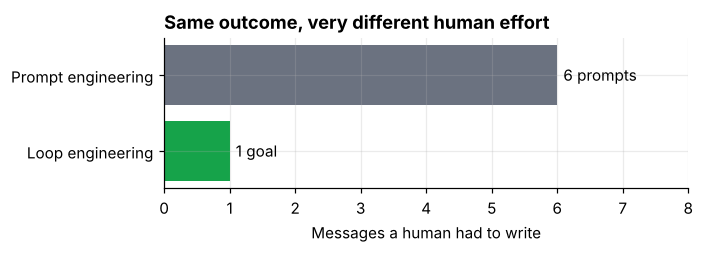

In [17]:
s1b = fresh_store()
r1 = run_loop(s1b, make_request(s1b, "R1", "cancel", "Please cancel my headphones order.", order_id="A1001"),
              spine=True, title="Loop engineering: one goal, the loop drives")

fig, ax = plt.subplots(figsize=(6.5, 2.4))
bars = ax.barh(["Loop engineering", "Prompt engineering"], [1, len(manual_session)],
               color=[COLORS["green"], COLORS["grey"]])
ax.bar_label(bars, labels=["1 goal", f"{len(manual_session)} prompts"], padding=4)
ax.set_xlabel("Messages a human had to write"); ax.set_xlim(0, 8)
ax.set_title("Same outcome, very different human effort", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

---
# Scenario 2. The core loop: Goal, Act, Observe, Adjust

Read each row left to right: the goal check, the one action the agent chose, what it observed, and how that observation changed its next decision.

**2a.** A simple cancellation before shipping.

In [18]:
s2 = fresh_store()
r2a = run_loop(s2, make_request(s2, "R2a", "cancel", "Please cancel my headphones order, I found them cheaper.", order_id="A1001"),
               spine=True, title="2a. Cancel before shipping")

**2b.** Leo asks to cancel, but his shoes have already shipped. Watch pass 1 fail and pass 2 **adjust**: the agent switches from cancelling to a return, and the refund changes because shipping is not refundable on returns.

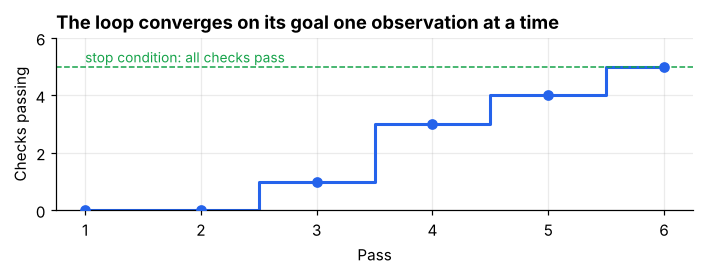

In [19]:
r2b = run_loop(s2, make_request(s2, "R2b", "cancel", "Cancel my running shoes order please, I changed my mind.", order_id="A1002"),
               spine=True, title="2b. Cancel after shipping: the agent adjusts")

passes = [t["pass_no"] for t in r2b.trace]
passing = [sum(1 for _, v in t["checks"] if v is True) for t in r2b.trace]
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.step(passes, passing, where="mid", color=COLORS["blue"], lw=2)
ax.scatter(passes, passing, color=COLORS["blue"], zorder=3)
ax.axhline(len(r2b.trace[0]["checks"]), color=COLORS["green"], ls="--", lw=1)
ax.text(passes[0], len(r2b.trace[0]["checks"]) + 0.15, "stop condition: all checks pass", color=COLORS["green"], fontsize=9)
ax.set_xlabel("Pass"); ax.set_ylabel("Checks passing"); ax.set_ylim(0, 6); ax.set_xticks(passes)
ax.set_title("The loop converges on its goal one observation at a time", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

---
# Scenario 3. Weak goals vs verifiable goals

Same request (cancel Maya's order), same agent, three different goals:

* **"Cancel the order"** is too narrow: it is verifiable, but it stops before the customer is refunded.
* **"Make the customer happy"** has no test at all, so the loop can never declare success. Watch what it does instead.
* **The verifiable goal** checks state, refund, stock and email, and stops exactly when the job is done.

In [20]:
def goal_cancel_only(store, req):
    return [("Order status is cancelled", store.order(req["order_id"])["status"] == "cancelled")]
goal_cancel_only.label = 'Weak: "Cancel the order"'


def goal_customer_happy(store, req):
    return [("Customer is happy", None)]          # None = no way to test it
goal_customer_happy.label = 'Weak: "Make the customer happy" (no test)'

runs3 = []
for g in (goal_cancel_only, goal_customer_happy, goal_resolved):
    s = fresh_store()
    r = run_loop(s, make_request(s, "R3", "cancel", "Please cancel my headphones order.", order_id="A1001"),
                 goal=g, spine=False, show=False)
    runs3.append((g.label, r))

outcome_cards([(lbl, r, "Judged afterwards against the real business checks") for lbl, r in runs3])
show_trace_collapsed(runs3[0][1], runs3[0][0])
show_trace_collapsed(runs3[1][1], runs3[1][0])

Pass,1. Goal check,2. Act,3. Observe,4. Adjust (next decision)
1,0/1 checks,cancel_order order_id=A1001,✓ status: cancelled,Order is closed; refund the customer. Amount $138.95: full total including shipping (cancelled before shipping).
2,0/1 checks,"issue_refund order_id=A1001, amount=$138.95",✓ Refunded $138.95 (TX1009),Refund done; put the stock back.
3,0/1 checks,restock order_id=A1001,✓ restocked: ['HEADPHONES'],Tell the customer what happened.
4,0/1 checks,"send_email order_id=A1001, subject=Order A1001 cancelled","✓ sent_to: A1001, subject: Order A1001 cancelled",Every step in my plan is done.
5,0/1 checks,finish,✗ Goal not met: Customer is happy (no test),"The goal cannot be measured, so try to please the customer again."
6,0/1 checks,"send_email order_id=A1001, subject=Anything else we can do?","✓ sent_to: A1001, subject: Anything else we can do?",Every step in my plan is done.
7,0/1 checks,finish,✗ Goal not met: Customer is happy (no test),"The goal cannot be measured, so try to please the customer again."
8,0/1 checks,"send_email order_id=A1001, subject=Anything else we can do?","✓ sent_to: A1001, subject: Anything else we can do?",Every step in my plan is done.
9,0/1 checks,finish,✗ Goal not met: Customer is happy (no test),"The goal cannot be measured, so try to please the customer again."
10,0/1 checks,"send_email order_id=A1001, subject=Anything else we can do?","✓ sent_to: A1001, subject: Anything else we can do?",STOPPED at the 10 pass limit


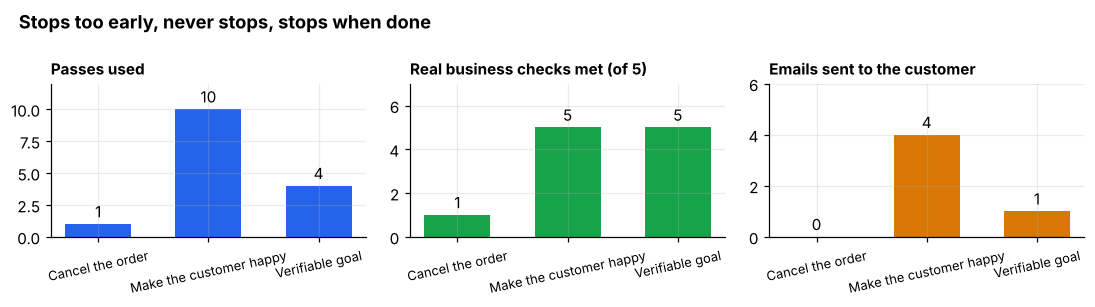

In [21]:
labels = ["Cancel the order", "Make the customer happy", "Verifiable goal"]
passes = [r.passes for _, r in runs3]
emails = [business_view(r.store, r.request)["emails"] for _, r in runs3]
real = [sum(1 for _, v in goal_resolved(r.store, r.request) if v is True) for _, r in runs3]

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, vals, title, color in zip(axes, [passes, real, emails],
                                  ["Passes used", "Real business checks met (of 5)", "Emails sent to the customer"],
                                  [COLORS["blue"], COLORS["green"], COLORS["amber"]]):
    b = ax.bar(range(3), vals, color=color, width=0.6)
    ax.bar_label(b, padding=2); ax.set_xticks(range(3), labels, fontsize=8.5, rotation=12)
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold"); ax.set_ylim(0, max(vals) + 2)
fig.suptitle("Stops too early, never stops, stops when done", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

In [22]:
callout("What happened",
        "The narrow goal stopped after one pass and Maya never got her money. The untestable goal kept 'trying to please' "
        "the customer, spamming her inbox until the pass limit. Only the verifiable goal finished the job and stopped.",
        COLORS["amber"])

---
# Scenario 4. Triggers: hooks and schedules

Something has to start the loop. Here we simulate two days of a shop's life:

* A **hook** fires whenever a customer message arrives, classifies it and runs the loop.
* A **schedule** runs a nightly reconciliation job at 02:00 that looks for stuck orders: returns received but never refunded.

In [23]:
import re


class EventBus:
    """Event driven triggers: register a hook, emit an event, the hook runs."""
    def __init__(self):
        self.hooks, self.timeline = {}, []

    def on(self, event, fn):
        self.hooks.setdefault(event, []).append(fn)

    def emit(self, event, payload, at):
        for fn in self.hooks.get(event, []):
            fn(payload, at)


class Scheduler:
    """Time driven triggers: a simulated clock that runs jobs at set hours (like cron)."""
    def __init__(self):
        self.jobs = []

    def every_day_at(self, hour, name, fn):
        self.jobs.append((hour, name, fn))

    def simulate(self, start, days, bus, events):
        clock_events = [(at, "message", p) for at, p in events]
        for d in range(days):
            for hour, name, fn in self.jobs:
                clock_events.append((start + timedelta(days=d, hours=hour), "job", (name, fn)))
        for at, kind, payload in sorted(clock_events, key=lambda x: x[0]):
            if kind == "message":
                bus.emit("customer_message", payload, at)
            else:
                payload[1](at)


def classify(message):
    oid = re.search(r"A\d{4}", message)
    kind = "return_item" if "return" in message.lower() else "cancel"
    return kind, oid.group(0) if oid else None


s4, bus, cron = fresh_store(), EventBus(), Scheduler()
runs4 = []


def on_customer_message(payload, at):
    kind, oid = classify(payload["text"])
    req = make_request(s4, f"MSG-{len(runs4) + 1}", kind, payload["text"], order_id=oid)
    r = run_loop(s4, req, spine=True, checker=CheckerSubagent(), show=False)
    runs4.append(("HOOK", at, f'{payload["from"]}: &ldquo;{payload["text"]}&rdquo;', r))


def nightly_reconciliation(at):
    stuck = s4.q("SELECT id FROM orders WHERE status='returned' AND refunded=0")
    if not stuck:
        runs4.append(("SCHEDULE", at, "Nightly reconciliation: nothing stuck", None))
    for row in stuck:
        req = make_request(s4, f"NIGHT-{row['id']}", "return_item", f"Reconciliation: {row['id']} returned but never refunded", order_id=row["id"])
        r = run_loop(s4, req, spine=True, checker=CheckerSubagent(), show=False)
        runs4.append(("SCHEDULE", at, f"Nightly reconciliation found stuck order {row['id']}", r))


bus.on("customer_message", on_customer_message)
cron.every_day_at(2, "reconciliation", nightly_reconciliation)

start = datetime(2026, 10, 26)
cron.simulate(start, days=2, bus=bus, events=[
    (start + timedelta(hours=9, minutes=12), {"from": "Maya Chen", "text": "Hi, please cancel order A1001."}),
    (start + timedelta(hours=14, minutes=40), {"from": "Leo Park", "text": "Can you cancel A1002? I changed my mind."}),
])

rows = []
for trig, at, what, r in runs4:
    tcolor = COLORS["purple"] if trig == "HOOK" else COLORS["teal"]
    outcome = pill(r.status, status_color(r.status)) + f' <span style="color:#6b7280;font-size:12px">{r.passes} passes</span>' if r else pill("no work", COLORS["grey"])
    rows.append(f'<div style="display:flex;gap:12px;align-items:center;padding:8px 0;border-bottom:1px solid #f1f5f9">'
                f'<div style="width:120px;color:#6b7280;font-size:12px">{at:%a %d %b %H:%M}</div>'
                f'<div style="width:90px">{pill(trig, tcolor)}</div><div style="flex:1;font-size:13px">{what}</div><div>{outcome}</div></div>')
display(HTML(f'<div style="border:1px solid #e5e7eb;border-radius:12px;padding:8px 14px;max-width:900px">'
             f'<div style="font-weight:700;margin:4px 0">Two simulated days at the order desk</div>{"".join(rows)}</div>'))

In [24]:
night = [r for trig, _, _, r in runs4 if trig == "SCHEDULE" and r]
show_trace(night[0], "The scheduled job resolving a stuck return (nobody asked; the schedule did)")

---
# Scenario 5. Context engineering and skills

Zoe returns her coffee grinder. Her order has a long history: 40 tracking scans and 8 emails. We run the same loop twice with the same agent: once with **naive** context (everything, every time) and once with **engineered** context (compacted history, skill index plus only the matching skill, the spine instead of raw logs).

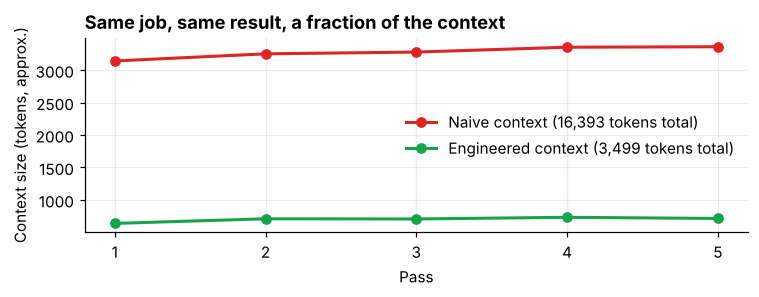

In [25]:
runs5 = {}
for label, ctx in (("Naive context", naive_context), ("Engineered context", engineered_context())):
    s = fresh_store()
    req = make_request(s, "R5", "cancel", "I'd like to cancel and send back the coffee grinder.", order_id="A1005")
    runs5[label] = run_loop(s, req, context=ctx, spine=True, show=False)

fig, ax = plt.subplots(figsize=(7, 2.8))
for label, color in (("Naive context", COLORS["red"]), ("Engineered context", COLORS["green"])):
    toks = [t["tokens"] for t in runs5[label].trace if "action" in t]
    ax.plot(range(1, len(toks) + 1), toks, marker="o", color=color, lw=2, label=f"{label} ({sum(toks):,} tokens total)")
ax.set_xticks(range(1, len(toks) + 1))
ax.set_xlabel("Pass"); ax.set_ylabel("Context size (tokens, approx.)"); ax.legend(frameon=False)
ax.set_title("Same job, same result, a fraction of the context", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

outcome_cards([(k, r, "Both reach the same outcome") for k, r in runs5.items()])

In [26]:
def context_breakdown(ctx, title):
    secs = [(n, len(t) // 4) for n, t in ctx.sections()]
    total, top = sum(v for _, v in secs), max(v for _, v in secs)
    bars = "".join(f'<div style="display:flex;align-items:center;gap:8px;font-size:12px;margin:2px 0">'
                   f'<div style="width:170px;color:#374151">{n}</div>'
                   f'<div style="background:{COLORS["blue"]};height:10px;border-radius:3px;width:{max(2, 260 * v / top):.0f}px"></div>'
                   f'<div style="color:#6b7280">{v:,}</div></div>' for n, v in secs)
    return (f'<div style="border:1px solid #e5e7eb;border-radius:12px;padding:10px 14px;min-width:420px">'
            f'<div style="font-weight:700">{title}</div><div style="color:#6b7280;font-size:12px;margin-bottom:6px">'
            f'{total:,} tokens on the last pass</div>{bars}</div>')

side_by_side(*(context_breakdown([t for t in r.trace if "action" in t][-1]["context"], k) for k, r in runs5.items()))

**Skills and progressive disclosure.** The agent always sees the one-line skill index. A skill's full `SKILL.md` body is loaded only when the request matches it.

In [27]:
s5 = fresh_store()
cards = []
for kind, rid, oid, skus, cust in (("place", "P", None, ["KETTLE"], "Ava Singh"), ("cancel", "C", "A1001", None, None)):
    req = make_request(s5, rid, kind, "", order_id=oid, skus=skus, customer=cust)
    ctx = engineered_context()(s5, req, None, None, [])
    loaded = [n for n in SKILLS if n in ctx.docs]
    items = "".join(f'<div style="font-size:12.5px;padding:2px 0">{pill("loaded", COLORS["green"]) if n in loaded else pill("index only", COLORS["grey"])} {n}</div>' for n in SKILLS)
    cards.append(f'<div style="border:1px solid #e5e7eb;border-radius:12px;padding:10px 14px;min-width:260px">'
                 f'<div style="font-weight:700;margin-bottom:6px">Request kind: {kind}</div>{items}'
                 f'<div style="color:#6b7280;font-size:12px;margin-top:6px">Context: {ctx.tokens():,} tokens</div></div>')
side_by_side(*cards)

---
# Scenario 6. The spine: `progress.md`

Ethan cancels his smart watch. This time the payment gateway **times out after the money has already moved**: the refund happened, but the agent is told "outcome unknown".

Our loop gives the agent a fresh context every pass (like most production loops). Without a spine, all it knows is the last observation, so it simply retries. With a spine, `progress.md` tells it the last refund's outcome is unknown, so it checks the ledger first.

In [28]:
runs6 = {}
for label, use_spine in (("No spine", False), ("With spine (progress.md)", True)):
    s = fresh_store()
    s.gateway.fail_next("after")                     # money moves, response is lost
    req = make_request(s, "R6", "cancel", "Please cancel my smart watch order.", order_id="A1006")
    runs6[label] = run_loop(s, req, spine=use_spine, show=True, title=f"6. {label}")

outcome_cards([(k, r, "Gateway timed out after processing the refund") for k, r in runs6.items()])

Pass,1. Goal check,2. Act,3. Observe,4. Adjust (next decision)
1,0/5 checks,cancel_order order_id=A1006,✓ status: cancelled,Order is closed; refund the customer. Amount $260.00: full total including shipping (cancelled before shipping).
2,1/5 checks,"issue_refund order_id=A1006, amount=$260.00",✗ Payment gateway timed out. The outcome is unknown.,"Last attempt timed out, so try again. Amount $260.00: full total including shipping (cancelled before shipping)."
3,3/5 checks,"issue_refund order_id=A1006, amount=$260.00",✓ Refunded $260.00 (TX1010),Refund done; put the stock back.
4,1/5 checks,restock order_id=A1006,✓ restocked: ['WATCH'],Tell the customer what happened.
5,2/5 checks,"send_email order_id=A1006, subject=Order A1006 cancelled","✓ sent_to: A1006, subject: Order A1006 cancelled",Every step in my plan is done.
6,3/5 checks,finish,✗ Goal not met: Refund matches policy ($260.00); Exactly one refund,The goal check still fails and I cannot undo it. Hand over to a person.
7,3/5 checks,escalate order_id=A1006,✓ ticket: ESC-001,ESCALATED to a person


In [29]:
side_by_side(*(df_html(r.store.table("ledger").query("order_id == 'A1006'"), f"Ledger for A1006: {k}", "amount")
               for k, r in runs6.items()))
display(Markdown("**The spine the agent read on every pass** (`" + runs6["With spine (progress.md)"].spine.path + "`):\n\n"
                 + runs6["With spine (progress.md)"].spine.markdown()))

ref,order_id,type,amount
TX1005,A1006,charge,260.0
TX1009,A1006,refund,260.0
TX1010,A1006,refund,260.0
ref,order_id,type,amount
TX1005,A1006,charge,260.0
TX1009,A1006,refund,260.0


**The spine the agent read on every pass** (`loop_workspace/progress_R6.md`):

# progress.md: request R6
- pass 1: cancel_order: OK
- pass 2: issue_refund $260.00: TIMEOUT, outcome unknown. Verify before retrying.
- pass 3: check_payments: OK (found $260.00 already refunded)
- pass 4: restock: OK
- pass 5: send_email: OK

---
# Scenario 7. Tools: MCP-style schemas, validation and a usage log

Every tool the agent can call is described by a schema like this one. It is the contract between the model and the outside world, whether you serve it through **MCP** or plain **API tool calling**.

In [30]:
spec = {k: v for k, v in TOOLS["issue_refund"].items() if k != "fn"}
display(Markdown("```json\n" + json.dumps({"name": "issue_refund", **spec}, indent=2) + "\n```"))

s7 = fresh_store()
for name, args in (("issue_refund", {"order_id": "A1001"}), ("delete_database", {}), ("get_order", {"order_id": "A1001"})):
    res = call_tool(s7, name, args)
    color = COLORS["green"] if res["ok"] else COLORS["red"]
    display(HTML(f'<div style="font-size:13px;margin:3px 0"><code>{name}({json.dumps(args)})</code> &rarr; '
                 f'<span style="color:{color}">{describe_entry({"tool": name, "args": args, **res})}</span></div>'))
print(f"\nThe same {len(claude_tools())} schemas are passed to Claude when USE_CLAUDE = True.")

```json
{
  "name": "issue_refund",
  "description": "Refund money to the customer through the payment gateway. Irreversible.",
  "input_schema": {
    "type": "object",
    "properties": {
      "order_id": {
        "type": "string"
      },
      "amount": {
        "type": "number"
      },
      "reason": {
        "type": "string"
      }
    },
    "required": [
      "order_id",
      "amount"
    ]
  }
}
```


The same 10 schemas are passed to Claude when USE_CLAUDE = True.


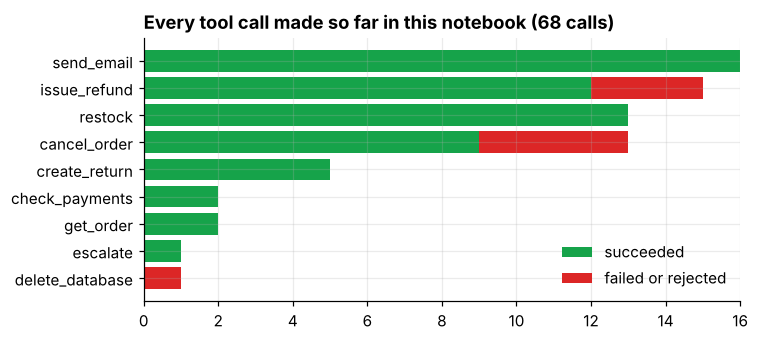

In [31]:
log = pd.DataFrame(TOOL_LOG)
counts = log.groupby(["tool", "ok"]).size().unstack(fill_value=0).reindex(columns=[True, False], fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(counts.index, counts[True], color=COLORS["green"], label="succeeded")
ax.barh(counts.index, counts[False], left=counts[True], color=COLORS["red"], label="failed or rejected")
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Every tool call made so far in this notebook ({len(log)} calls)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

---
# Scenario 8. A checker subagent

Isla returns one item (a $25 water bottle) from a two item order with $15 shipping. To simulate a maker agent with a knowledge gap, its refund skill is switched off, so it guesses "items plus shipping".

Refunds are **irreversible**, so the checker reviews the proposed action *before* it runs.

In [32]:
runs8 = {}
for label, checker in (("Maker alone", None), ("Maker + checker subagent", CheckerSubagent())):
    s = fresh_store()
    req = make_request(s, "R8", "return_item", "The water bottle leaks. I'm sending it back, please refund it.",
                       order_id="A1008", skus=["BOTTLE"])
    runs8[label] = run_loop(s, req, context=engineered_context(skills=False), spine=True, checker=checker,
                            title=f"8. {label}")
outcome_cards([(k, r, "Maker has no refund rules loaded") for k, r in runs8.items()])
callout("Why the checker is a separate agent",
        f"It has its own instructions (&ldquo;{CheckerSubagent.instructions}&rdquo;) and its own small context: the policy and the "
        "proposed action, not the maker's reasoning. In production it could run on a different model.", COLORS["purple"])

Pass,1. Goal check,2. Act,3. Observe,4. Adjust (next decision)
1,0/5 checks,"create_return order_id=A1008, skus=['BOTTLE']",✓ status: returned,"Order is closed; refund the customer. Amount $40.00: items plus shipping (my best guess, no refund rules loaded)."
2,1/5 checks,"issue_refund order_id=A1008, amount=$40.00",✓ Refunded $40.00 (TX1009),Refund done; put the stock back.
3,2/5 checks,restock order_id=A1008,✓ restocked: ['BOTTLE'],Tell the customer what happened.
4,3/5 checks,"send_email order_id=A1008, subject=Order A1008 returned","✓ sent_to: A1008, subject: Order A1008 returned",Every step in my plan is done.
5,4/5 checks,finish,✗ Goal not met: Refund matches policy ($25.00),The goal check still fails and I cannot undo it. Hand over to a person.
6,4/5 checks,escalate order_id=A1008,✓ ticket: ESC-001,ESCALATED to a person


---
# Scenario 9. Intent debt and `AGENTS.md`

Omar bought a jacket 45 days ago and wants his money back, angrily. The refund window is 30 days.

**Run A** uses a goal that sounds reasonable ("the customer gets their money back") and no `AGENTS.md`. **Run B** loads `AGENTS.md` and uses the verifiable policy goal.

In [33]:
def goal_money_back(store, req):
    o = store.order(req["order_id"])
    return [("Customer got money back", o["refunded"] > 0), ("Customer emailed", bool(store.emails(o["id"])))]
goal_money_back.label = 'Plausible but intent-blind: "Customer gets their money back"'

msg9 = "This jacket is rubbish. I want my money back NOW or I'm leaving a 1 star review."
runs9 = {}
for label, goal, intent in (("A. No AGENTS.md", goal_money_back, False), ("B. With AGENTS.md", goal_resolved, True)):
    s = fresh_store()
    req = make_request(s, "R9", "return_item", msg9, order_id="A1009")
    runs9[label] = run_loop(s, req, goal=goal, context=engineered_context(intent=intent), spine=True, title=f"9{label}")

outcome_cards([(k, r, "The loop's own verdict is the status pill") for k, r in runs9.items()])
callout("Both loops reported DONE",
        "Run A met its goal perfectly and refunded $180 the business had decided not to refund. The fix was technically sound "
        "and wrong for the business: that is intent debt. Writing the intent down in AGENTS.md is the human's job.", COLORS["red"])

---
# Scenario 10. Keeping a human in the loop

Grace cancels a $780 monitor order. `AGENTS.md` says refunds over $500 need a person. The loop pauses and shows a **review card**: everything a reviewer needs to make a real decision instead of rubber-stamping (the antidote to cognitive surrender).

Set `INTERACTIVE_HUMAN = True` in the setup cell to make the decision yourself.

In [34]:
s10 = fresh_store()
req10 = make_request(s10, "R10", "cancel", "Please cancel the monitor, I ordered the wrong size.", order_id="A1010")
r10 = run_loop(s10, req10, spine=True, checker=CheckerSubagent(), gate=human_gate("approve"), title="10a. Reviewer approves")

Customer,Grace Lee
Order,"A1010 (cancelled, placed 1 day ago)"
Customer asked,"Please cancel the monitor, I ordered the wrong size."
Agent proposes,Refund $780.00
Policy says,"$780.00: cancelled before shipping, so the full total including shipping"
Already refunded,$0.00
If approved,Money leaves the business. This cannot be undone.


In [35]:
def explain_changes(store, req):
    """A plain-language summary of what the loop changed, for the human who reads the output."""
    before, after = req["snapshot"], store.order(req["order_id"])
    lines = [f"Order **{after['id']}** went from *{before['status']}* to *{after['status']}*."]
    lines += [f"Refund **{r['ref']}** of **${r['amount']:.2f}** left the business." for r in store.refunds(after["id"])]
    if after["restocked"] and not before["restocked"]:
        lines.append("Stock was returned to inventory for: " + ", ".join(i["name"] for i in after["items"]) + ".")
    lines += [f"Email sent: *{e['subject']}*." for e in store.emails(after["id"])]
    expected, why = policy_refund(req)
    ok_ = abs(after["refunded"] - expected) < 0.005
    lines.append(("Policy check passed: " if ok_ else "**Policy check FAILED**: ") + f"expected ${expected:.2f} ({why}).")
    return "\n".join(f"- {l}" for l in lines)

display(Markdown("**What changed (read this before you ship):**\n\n" + explain_changes(s10, req10)))

**What changed (read this before you ship):**

- Order **A1010** went from *paid* to *cancelled*.
- Refund **TX1009** of **$780.00** left the business.
- Stock was returned to inventory for: 27 inch monitor.
- Email sent: *Order A1010 cancelled*.
- Policy check passed: expected $780.00 (cancelled before shipping, so the full total including shipping).

In [36]:
s10b = fresh_store()
r10b = run_loop(s10b, make_request(s10b, "R10b", "cancel", "Please cancel the monitor, I ordered the wrong size.", order_id="A1010"),
                spine=True, checker=CheckerSubagent(), gate=human_gate("deny"), title="10b. Reviewer denies: the loop hands over")

Customer,Grace Lee
Order,"A1010 (cancelled, placed 1 day ago)"
Customer asked,"Please cancel the monitor, I ordered the wrong size."
Agent proposes,Refund $780.00
Policy says,"$780.00: cancelled before shipping, so the full total including shipping"
Already refunded,$0.00
If approved,Money leaves the business. This cannot be undone.


Pass,1. Goal check,2. Act,3. Observe,4. Adjust (next decision)
1,0/5 checks,cancel_order order_id=A1010,✓ status: cancelled,Order is closed; refund the customer. Amount $780.00: full total including shipping (cancelled before shipping).
2,1/5 checks,"issue_refund order_id=A1010, amount=$780.00",✗ Human reviewer denied the refund,"This refund is outside policy. Tell the customer why, politely."
3,1/5 checks,"send_email order_id=A1010, subject=About your refund request for A1010","✓ sent_to: A1010, subject: About your refund request for A1010",Hand this case to a person.
4,2/5 checks,escalate order_id=A1010,✓ ticket: ESC-001,ESCALATED to a person


---
# Scenario 11. Everything together

Seven customers write in. Every message fires the hook, and every loop runs with the full engineering: engineered context and skills, `AGENTS.md`, a spine, a checker subagent and a human gate. Two of them hit payment gateway timeouts on purpose. This run uses a database file, `loop_workspace/shop.db`, so you can open it afterwards in any SQLite browser.

In [37]:
s11 = fresh_store(os.path.join(WORKSPACE, "shop.db"))
inbox = [
    dict(customer="Ava Singh", kind="place", skus=["KETTLE"], text="I'd like to buy the electric kettle.", chaos="before"),
    dict(customer="Maya Chen", kind="cancel", order_id="A1001", text="Please cancel my headphones."),
    dict(customer="Leo Park", kind="cancel", order_id="A1002", text="Cancel my shoes, please."),
    dict(customer="Isla Ward", kind="return_item", order_id="A1008", skus=["BOTTLE"], text="Returning the leaky bottle."),
    dict(customer="Ethan Ali", kind="cancel", order_id="A1006", text="Cancel the smart watch.", chaos="after"),
    dict(customer="Omar Haddad", kind="return_item", order_id="A1009", text="I want my money back for the jacket."),
    dict(customer="Grace Lee", kind="cancel", order_id="A1010", text="Cancel the monitor, wrong size."),
]
approvals = []


def counting_gate(action, req, store):
    d = human_gate("approve", show=False)(action, req, store)
    if d is not None:
        approvals.append(req["id"])
    return d


runs11 = []
for i, m in enumerate(inbox, 1):
    if m.get("chaos"):
        s11.gateway.fail_next(m["chaos"])
    req = make_request(s11, f"R11-{i}", m["kind"], m["text"], order_id=m.get("order_id"), skus=m.get("skus"), customer=m["customer"])
    runs11.append((m, run_loop(s11, req, spine=True, checker=CheckerSubagent(), gate=counting_gate, show=False)))

rows = []
for m, r in runs11:
    b = business_view(s11, r.request)
    exp = b["expected"] or 0
    money_ok = abs(b["refunded"] - exp) < 0.005
    human = ("approved a refund" if r.request["id"] in approvals else "took over (escalation)" if b["escalated"] else "not needed")
    chaos = pill("gateway timeout " + m["chaos"], COLORS["amber"]) if m.get("chaos") else ""
    if r.request["kind"] == "place":
        refund = pill(f"charged {b['charges']}x, no refund due", COLORS["green"] if b["charges"] == 1 else COLORS["red"])
    else:
        refund = pill(f"${b['refunded']:.2f} of ${exp:.2f}", COLORS["green"] if money_ok else COLORS["red"])
    rows.append([m["customer"], f'{m["text"]} {chaos}', pill(r.status, status_color(r.status)), r.passes, refund, human])
dash = pd.DataFrame(rows, columns=["Customer", "Request", "Outcome", "Passes", "Refund vs policy", "Human"])
display(HTML(df_html(dash, "Order desk: seven requests, one engineered loop")))

Customer,Request,Outcome,Passes,Refund vs policy,Human
Ava Singh,I'd like to buy the electric kettle. gateway timeout before,DONE,3,"charged 1x, no refund due",not needed
Maya Chen,Please cancel my headphones.,DONE,4,$138.95 of $138.95,not needed
Leo Park,"Cancel my shoes, please.",DONE,5,$149.00 of $149.00,not needed
Isla Ward,Returning the leaky bottle.,DONE,4,$25.00 of $25.00,not needed
Ethan Ali,Cancel the smart watch. gateway timeout after,DONE,5,$260.00 of $260.00,not needed
Omar Haddad,I want my money back for the jacket.,DONE,2,$0.00 of $0.00,took over (escalation)
Grace Lee,"Cancel the monitor, wrong size.",DONE,4,$780.00 of $780.00,approved a refund


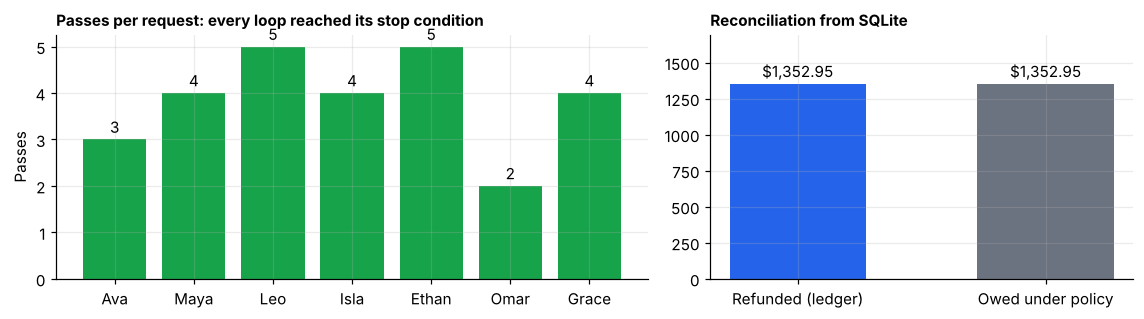

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3), gridspec_kw={"width_ratios": [1.4, 1]})
names = [m["customer"].split()[0] for m, _ in runs11]
b = ax1.bar(names, [r.passes for _, r in runs11], color=[status_color(r.status) for _, r in runs11])
ax1.bar_label(b, padding=2); ax1.set_ylabel("Passes")
ax1.set_title("Passes per request: every loop reached its stop condition", loc="left", fontsize=10, fontweight="bold")

led = pd.read_sql("SELECT type, ROUND(SUM(amount),2) AS amount FROM ledger GROUP BY type", s11.db)
expected_refunds = sum((business_view(s11, r.request)["expected"] or 0) for _, r in runs11)
vals = [led.set_index("type").loc["refund", "amount"], expected_refunds]
b2 = ax2.bar(["Refunded (ledger)", "Owed under policy"], vals, color=[COLORS["blue"], COLORS["grey"]], width=0.55)
ax2.bar_label(b2, labels=[f"${v:,.2f}" for v in vals], padding=2); ax2.set_ylim(0, max(vals) * 1.25)
ax2.set_title("Reconciliation from SQLite", loc="left", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

callout("Reconciled", f"Refunds in the database match policy exactly: ${vals[0]:,.2f}. "
        f"Two gateway timeouts, no double charges, no double refunds. Humans touched {len(approvals)} approval(s) and "
        f"{sum(1 for _, r in runs11 if r.status.startswith('ESCALATED') or business_view(s11, r.request)['escalated'])} escalation(s).", COLORS["green"])

In [39]:
# The raw SQL behind the dashboard: query the database yourself
display(HTML(df_html(pd.read_sql("""
    SELECT o.id, o.customer, o.status, o.total, o.refunded,
           (SELECT COUNT(*) FROM outbox e WHERE e.order_id = o.id) AS emails,
           (SELECT COUNT(*) FROM escalations x WHERE x.order_id = o.id) AS escalations
    FROM orders o ORDER BY o.id""", s11.db), "SELECT ... FROM orders (loop_workspace/shop.db)", "refunded")))

id,customer,status,total,refunded,emails,escalations
A1001,Maya Chen,cancelled,138.95,138.95,1,0
A1002,Leo Park,returned,161.0,149.0,1,0
A1004,Noah Kim,returned,67.0,0.0,0,0
A1005,Zoe Brown,shipped,99.0,0.0,0,0
A1006,Ethan Ali,cancelled,260.0,260.0,1,0
A1008,Isla Ward,returned,85.0,25.0,1,0
A1009,Omar Haddad,delivered,192.0,0.0,1,1
A1010,Grace Lee,cancelled,780.0,780.0,1,0
A2001,Ava Singh,paid,78.95,0.0,1,0


---
# The Order Desk: an interactive Gradio app

This is the app to use in a live demo or a class. Pick a customer and an agent, switch parts of the loop on and off, choose whether the payment gateway misbehaves, and press **Run the loop**. The trace fills in pass by pass, and the tabs show the SQLite tables, the spine and exactly what the agent saw.

**Agent picker.** *Mock agent* works offline with no key. The Claude options need an API key (see the "connect a real Claude model" cell near the top). If you pick Claude without a key, the app tells you instead of failing.

Good experiments to try:

* **Ethan** with *timeout after processing*: run it with the spine off, then on.
* **Isla** with skills off: run it with the checker off, then on.
* **Omar** with the goal *"Customer gets their money back"*, `AGENTS.md` off and the checker off (watch $180 leak). Then switch only the checker back on, and finally use the verifiable goal with `AGENTS.md` on.
* **Grace** with the human gate set to *deny*.
* **Maya** with the goal *"Make the customer happy"*. Count the emails in the Database tab.
* **Any of the above with Claude** instead of the mock agent. Does the real model make the same mistake? Does the loop still catch it when it does?

Use **Reset database** between experiments.

**Where it opens.** The app appears inside the notebook (Jupyter, JupyterLab, VS Code, Colab) and also at the local URL printed below the cell. Set `SHARE_LINK = True` to get a temporary public link you can send to a class; anyone with the link can use the app while this notebook is running, so turn it off afterwards. Static viewers such as GitHub cannot show the app.

In [ ]:
import html as html_lib
import queue
import threading

import gradio as gr

LAUNCH_APP = True      # set False to skip starting the app
SHARE_LINK = False     # True = temporary public URL for a class (anyone with the link can use it)

DESK_DB = os.path.join(WORKSPACE, "order_desk.db")
desk = {"store": fresh_store(DESK_DB), "n": 0}

PRESETS = {
    "Maya Chen: cancel headphones (A1001, not shipped)": dict(kind="cancel", order_id="A1001", text="Please cancel my headphones order."),
    "Leo Park: cancel shoes (A1002, already shipped)": dict(kind="cancel", order_id="A1002", text="Cancel my running shoes, I changed my mind."),
    "Noah Kim: stuck return (A1004)": dict(kind="return_item", order_id="A1004", text="I returned the lamp two weeks ago and still have no refund."),
    "Zoe Brown: return grinder (A1005, long history)": dict(kind="cancel", order_id="A1005", text="I'd like to send back the coffee grinder."),
    "Ethan Ali: cancel watch (A1006)": dict(kind="cancel", order_id="A1006", text="Please cancel my smart watch.", chaos="timeout after processing"),
    "Isla Ward: return one item (A1008)": dict(kind="return_item", order_id="A1008", skus=["BOTTLE"], text="The water bottle leaks, refund it please."),
    "Omar Haddad: refund after 45 days (A1009)": dict(kind="return_item", order_id="A1009", text="This jacket is rubbish. Money back NOW."),
    "Grace Lee: cancel $780 monitor (A1010)": dict(kind="cancel", order_id="A1010", text="Cancel the monitor, wrong size."),
    "Ava Singh: buy a kettle (new order)": dict(kind="place", customer="Ava Singh", skus=["KETTLE"], text="I'd like to buy the electric kettle."),
}
GOALS = {g.label: g for g in (goal_resolved, goal_cancel_only, goal_customer_happy, goal_money_back)}
CHAOS = {"none": None, "timeout before processing": "before", "timeout after processing": "after"}
AGENTS = {"Mock agent (offline, no key)": None, "Claude Sonnet 5.5": "claude-sonnet-5-5",
          "Claude Haiku 5.5": "claude-haiku-5-5", "Claude Opus 5.5": "claude-opus-5-5"}
PARTS = ["Spine (progress.md)", "Checker subagent", "AGENTS.md (intent)", "Skills", "Naive context (everything)"]
DEFAULT_PARTS = PARTS[:4]


def panel(inner):
    """Light card so the app reads well in both light and dark Gradio themes."""
    return f'<div style="background:#ffffff;color:#111827;border-radius:12px;padding:8px 12px">{inner}</div>'


def row(*blocks):
    return '<div style="display:flex;gap:18px;flex-wrap:wrap;align-items:flex-start">' + "".join(f"<div>{b}</div>" for b in blocks) + "</div>"


def db_view(store, req):
    oid = req.get("order_id") or ((store.find_by_customer(req.get("customer") or "") or {}).get("id"))
    blocks = [df_html(store.table("orders"), "orders", "status")]
    if oid:
        blocks.append(df_html(store.table("ledger").query("order_id == @oid"), f"ledger for {oid}", "amount"))
        blocks.append(df_html(store.table("outbox").query("order_id == @oid")[["id", "subject"]], f"outbox for {oid}"))
        blocks.append(df_html(store.table("escalations").query("order_id == @oid"), f"escalations for {oid}"))
    blocks.append(df_html(store.table("inventory"), "inventory", "stock"))
    return panel(row(*blocks))


def context_view(result):
    out = []
    for t in (t for t in result.trace if "action" in t):
        secs = "".join(f'<div style="margin:4px 0"><b>{html_lib.escape(n)}</b> <span style="color:#6b7280">({len(x) // 4:,} tokens)</span>'
                       f'<pre style="white-space:pre-wrap;font-size:11.5px;background:#f8fafc;color:#111827;padding:6px;border-radius:6px;max-height:180px;overflow:auto">{html_lib.escape(x)}</pre></div>'
                       for n, x in t["context"].sections())
        out.append(f'<details style="margin:4px 0"><summary style="cursor:pointer">Pass {t["pass_no"]}: {t["tokens"]:,} tokens, '
                   f'chose <code>{html_lib.escape(t["action"]["tool"])}</code></summary>{secs}</details>')
    return panel("".join(out) or "Nothing yet.")


def on_preset(preset):
    p = PRESETS[preset]
    return p["text"], p.get("chaos", "none")


def run_desk(preset, message, goal_label, gateway, agent_label, parts, gate_choice, max_passes, pause):
    """A generator: Gradio streams each yield to the page, so the trace fills in live."""
    store, p = desk["store"], PRESETS[preset]
    desk["n"] += 1
    model = AGENTS[agent_label]
    if model and not load_api_key():
        msg = callout_html("No API key found",
                           "Claude needs an Anthropic API key. Add it as the ANTHROPIC_API_KEY environment variable or a Colab secret, "
                           "run the 'connect a real Claude model' cell, then try again. Or pick the mock agent.", COLORS["red"])
        yield panel(msg), gr.update(), gr.update(), gr.update()
        return
    if p.get("order_id") and not store.order(p["order_id"]):
        yield panel(callout_html("Order not found", "Press Reset database and try again.", COLORS["red"])), gr.update(), gr.update(), gr.update()
        return
    agent = make_agent(model) if model else MockAgent()
    store.gateway.fail_next(CHAOS[gateway], 1 if CHAOS[gateway] else 0)
    req = make_request(store, f"APP-{desk['n']}", p["kind"], message, order_id=p.get("order_id"),
                       skus=p.get("skus"), customer=p.get("customer"))
    ctx = naive_context if PARTS[4] in parts else engineered_context(intent=PARTS[2] in parts, skills=PARTS[3] in parts)
    reviews = []

    def app_gate(action, req_, store_):
        if gate_choice == "off" or action["tool"] != "issue_refund" or float(action["args"].get("amount", 0)) <= APPROVAL_THRESHOLD:
            return None
        color = COLORS["green"] if gate_choice == "approve" else COLORS["red"]
        reviews.append(review_card(action, req_, store_) +
                       f'<div style="margin:-2px 0 8px 4px">Reviewer decision: {pill(gate_choice.upper(), color)}</div>')
        return {"approved": gate_choice == "approve"}

    # The loop runs in a worker thread and hands each pass to the page through a queue
    updates, ack = queue.Queue(), queue.Queue()

    def on_pass(partial):
        updates.put(("pass", partial))
        ack.get()                                   # wait until the page has drawn this pass

    def worker():
        try:
            r = run_loop(store, req, agent=agent, goal=GOALS[goal_label], context=ctx,
                         spine=PARTS[0] in parts, checker=CheckerSubagent() if PARTS[1] in parts else None,
                         gate=app_gate, max_passes=int(max_passes), show=False, on_pass=on_pass)
            updates.put(("done", r))
        except Exception as e:                      # e.g. a network or API error from Claude
            updates.put(("error", e))

    threading.Thread(target=worker, daemon=True).start()
    title = f"{preset.split(':')[0]} &middot; {agent_label}"
    while True:
        kind, value = updates.get()
        if kind == "pass":
            yield (panel(trace_html(value, title + " &middot; running") + "".join(reviews)),
                   db_view(store, req), gr.update(), panel("Available when the run finishes."))
            time.sleep(float(pause))
            ack.put(True)
        elif kind == "error":
            yield panel(callout_html("The run stopped with an error", html_lib.escape(repr(value)), COLORS["red"])), db_view(store, req), gr.update(), gr.update()
            return
        else:
            r = value
            spine_text = r.spine.markdown() if r.spine else "_The spine is switched off: the agent only sees the last observation._"
            yield (panel(trace_html(r, title) + "".join(reviews) + outcome_cards_html([("Outcome", r, "Judged against the real business checks")])),
                   db_view(store, req), spine_text, context_view(r))
            return


def reset_desk():
    desk["store"] = fresh_store(DESK_DB)
    note = panel('<div style="color:#6b7280">Database reset. Pick a customer and run the loop.</div>')
    return note, db_view(desk["store"], {"order_id": None, "customer": ""}), "", note


with gr.Blocks(title="The Order Desk") as order_desk:
    gr.HTML(f'<div style="border-radius:12px;padding:14px 18px;background:linear-gradient(90deg,{COLORS["blue"]},{COLORS["purple"]});color:white">'
            f'<div style="font-size:20px;font-weight:700">The Order Desk</div>'
            f'<div style="font-size:13px;opacity:.92">A loop engineered AI agent working on a live SQLite database. '
            f'Change one part of the loop at a time and watch what happens.</div></div>')
    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("**1. Who is writing in?**")
            preset = gr.Dropdown(list(PRESETS), value=list(PRESETS)[0], label="Customer")
            message = gr.Textbox(value=PRESETS[list(PRESETS)[0]]["text"], label="Message", lines=2)
            gr.Markdown("**2. What is the loop aiming for?**")
            goal_dd = gr.Dropdown(list(GOALS), value=goal_resolved.label, label="Goal")
            gateway = gr.Dropdown(list(CHAOS), value="none", label="Payment gateway")
        with gr.Column(scale=1):
            gr.Markdown("**3. Who is the agent, and what surrounds it?**")
            agent_dd = gr.Dropdown(list(AGENTS), value=list(AGENTS)[0], label="Agent")
            parts = gr.CheckboxGroup(PARTS, value=DEFAULT_PARTS, label="Loop parts switched on")
            gate = gr.Radio(["off", "approve", "deny"], value="approve", label=f"Human gate (refunds over ${APPROVAL_THRESHOLD:.0f})")
            with gr.Row():
                max_passes = gr.Slider(3, 15, value=10, step=1, label="Max passes")
                pause = gr.Slider(0, 1.5, value=0.4, step=0.1, label="Pause between passes (s)")
    with gr.Row():
        run_btn = gr.Button("Run the loop", variant="primary")
        reset_btn = gr.Button("Reset database")
    with gr.Tabs():
        with gr.Tab("Loop trace"):
            trace_out = gr.HTML(panel('<div style="color:#6b7280">Pick a customer and press Run the loop.</div>'))
        with gr.Tab("Database (SQLite)"):
            db_out = gr.HTML(db_view(desk["store"], {"order_id": None, "customer": ""}))
        with gr.Tab("progress.md"):
            spine_out = gr.Markdown()
        with gr.Tab("What the agent saw"):
            ctx_out = gr.HTML(panel("Run the loop to see each pass's context."))

    preset.change(on_preset, preset, [message, gateway])
    run_btn.click(run_desk, [preset, message, goal_dd, gateway, agent_dd, parts, gate, max_passes, pause],
                  [trace_out, db_out, spine_out, ctx_out])
    reset_btn.click(reset_desk, None, [trace_out, db_out, spine_out, ctx_out])

if LAUNCH_APP:
    order_desk.launch(inline=True, share=SHARE_LINK, prevent_thread_lock=True, height=980,
                      theme=gr.themes.Soft(), quiet=True)

When you are finished, stop the app (and any public link) by running the next cell.

In [ ]:
order_desk.close()

---
# Try it with a real model

1. Run the install cell, then add your key as described in "connect a real Claude model" near the top.
2. Either set `USE_CLAUDE = True` in the setup cell and rerun everything, or simply pick a Claude model in the Order Desk app.

The loop, tools, goals, spine, checker and gate stay exactly the same: only the agent inside the loop changes. Expect the real model to vary from run to run, and do not expect it to repeat the mock agent's mistakes on cue. That variability is the best argument for everything around the loop: verifiable goals, a spine, a checker and a human who reads the output.

A full run of every scenario is roughly a hundred model calls. Claude Haiku 5.5 is the cheapest way to experiment; Sonnet 5.5 is the default.

# Exercises

1. **Write a new goal.** Add a check to `goal_resolved` that the customer's email states the exact refund amount. Which runs now fail?
2. **Add a tool.** Create `issue_store_credit` and update `AGENTS.md` so late refunds are offered store credit instead of a flat decline.
3. **A model as the checker.** Rewrite `CheckerSubagent.review` to ask Claude Haiku to approve or reject the proposed refund, while Sonnet stays the maker. Does a different model catch different mistakes?
4. **New trigger.** Add a hook that fires when stock for a SKU drops below 3 and starts a reorder loop.

# References

* Martin Keen, *What Is Loop Engineering? Building Better AI Agents*, IBM Technology (YouTube): https://www.youtube.com/watch?v=DQBqh6gcx7U
* AGENTS.md, an open format for guiding coding agents: https://agents.md/
* Anthropic Engineering, *Equipping agents for the real world with Agent Skills*: https://www.anthropic.com/engineering/equipping-agents-for-the-real-world-with-agent-skills
* Model Context Protocol: https://modelcontextprotocol.io/introduction
* Gradio documentation: https://www.gradio.app/docs